In [1]:
#A

import jetset
print('JetSeT version:', jetset.__version__)

import warnings
warnings.filterwarnings('ignore')
import numpy as np
import matplotlib.pyplot as plt
# If in Jupyter: %matplotlib inline

from jetset.data_loader import Data, ObsData
from jetset.sed_shaper import SEDShape
from jetset.jet_model import Jet
from jetset.model_manager import FitModel
from jetset.minimizer import ModelMinimizer
from jetset.mcmc import McmcSampler

JetSeT version: 1.3.0


---> excluding  data_set/s ['-1']
filter -1 45
current datasets
dataset 0.0
---> data sets left after filtering None
---> data len after filtering=45


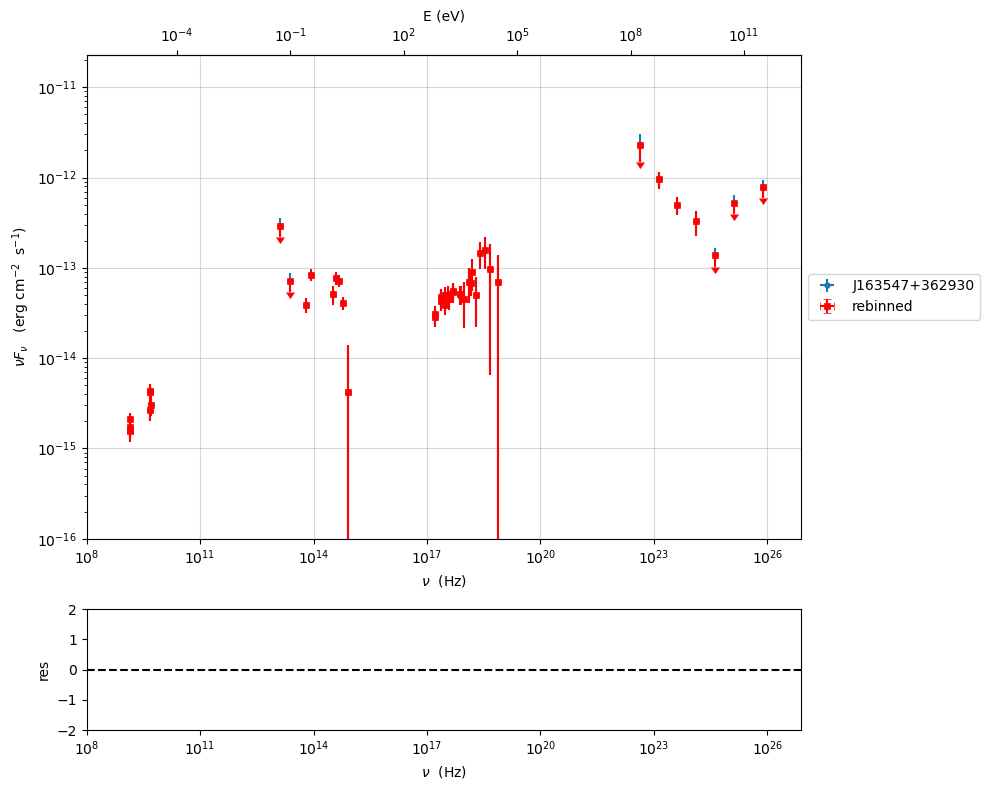

In [2]:
import jetset
import numpy as np
import matplotlib.pyplot as plt
from jetset.data_loader import Data, ObsData

# 1. Load the raw data from SED.txt
d = np.genfromtxt('SED.txt')
# Remove illogical Fermi point 
d = d[d[:, 0] != 1.709E22]

data = Data(n_rows=d.shape[0])
data.set_field('x', d[:, 0])
data.set_field('y', d[:, 1])
data.set_field('dy', d[:, 2])

data.set_meta_data('z', 3.647763)
data.set_meta_data('UL_CL', 0.95)
data.set_meta_data('restframe', 'obs')
data.set_meta_data('data_scale', 'lin-lin')
data.set_meta_data('obj_name', 'J163547+362930')

# 2. Create two independent ObsData objects
raw_data = ObsData(data_table=data)      # Keeps the original data untouched
sed_data = ObsData(data_table=data)      # This will be rebinned and processed

# 3. Plot the raw data first (default style)
myPlot = raw_data.plot_sed()

# 4. Process the rebinned data
sed_data.filter_data_set('-1', exclude=True)   # remove low-quality points
#sed_data.group_data(bin_width=0.15)
sed_data.add_systematics(0.15, [10.**6, 10.**29])

# Set upper limits (UL) by frequency
UL_freq = [
    1.324e25,   # gamma
    7.646e25,   # gamma
    4.188e24,   # gamma
    4.188e22,   # X-ray
    2.417e13,   # sub-mm
    1.318e13,   # sub-mm
]
for freq in UL_freq:
    mask = np.isclose(sed_data.table['nu_data'], freq, rtol=0.05)
    sed_data.table['UL'][mask] = True

# 5. Add the rebinned data to the same plot with custom style

myPlot.add_data_plot(
    sed_data, 
    label='rebinned', 
    color='red', 
    fmt='s',          # 's' for square markers
    ms=5,             # marker size
    mew=0.5           # marker edge width
)
myPlot.setlim(y_min=1E-16, x_min=1E8)
plt.show()


*** evaluating spectral indices for data ***


*** Log-Polynomial fitting of the synchrotron component ***
---> first blind fit run,  fit range: [9, 16]
---> class:  ISP

--> class:  LSP




model name,name,val,bestfit val,err +,err -,start val,fit range min,fit range max,frozen
LogParabolaEp,b,-8.256408e-02,-8.256408e-02,2.584721e-02,--,-6.224913e-02,-1.000000e+01,0.000000e+00,False
LogParabolaEp,Ep,1.330904e+01,1.330904e+01,5.717990e-01,--,1.413585e+01,0.000000e+00,3.000000e+01,False
LogParabolaEp,Sp,-1.333490e+01,-1.333490e+01,7.469589e-02,--,-1.320459e+01,-3.000000e+01,0.000000e+00,False
BBB,nuFnu_p_BBB,-1.338371e+01,-1.338371e+01,1.806069e-01,--,-1.320459e+01,-1.520459e+01,-1.120459e+01,False
BBB,nu_scale,4.312914e-02,4.312914e-02,6.422704e-03,--,0.000000e+00,-5.000000e-01,5.000000e-01,False


---> sync       nu_p=+1.330904e+01 (err=+5.717990e-01)  nuFnu_p=-1.333490e+01 (err=+7.469589e-02) curv.=-8.256408e-02 (err=+2.584721e-02)


*** Log-Polynomial fitting of the IC component ***
---> fit range: [16, 26]
---> LogCubic fit
====> simplex
====> migrad
====> simplex
====> migrad
====> simplex
====> migrad




model name,name,val,bestfit val,err +,err -,start val,fit range min,fit range max,frozen
LogCubic,b,-1.362857e-01,-1.362857e-01,2.137025e-02,--,-1.000000e+00,-1.000000e+01,0.000000e+00,False
LogCubic,c,-1.412340e-02,-1.412340e-02,3.894639e-03,--,-1.000000e+00,-1.000000e+01,1.000000e+01,False
LogCubic,Ep,2.206163e+01,2.206163e+01,1.234883e-01,--,2.324243e+01,0.000000e+00,3.000000e+01,False
LogCubic,Sp,-1.186960e+01,-1.186960e+01,1.075056e-01,--,-1.000000e+01,-3.000000e+01,0.000000e+00,False


---> IC         nu_p=+2.206163e+01 (err=+1.234883e-01)  nuFnu_p=-1.186960e+01 (err=+1.075056e-01) curv.=-1.362857e-01 (err=+2.137025e-02)



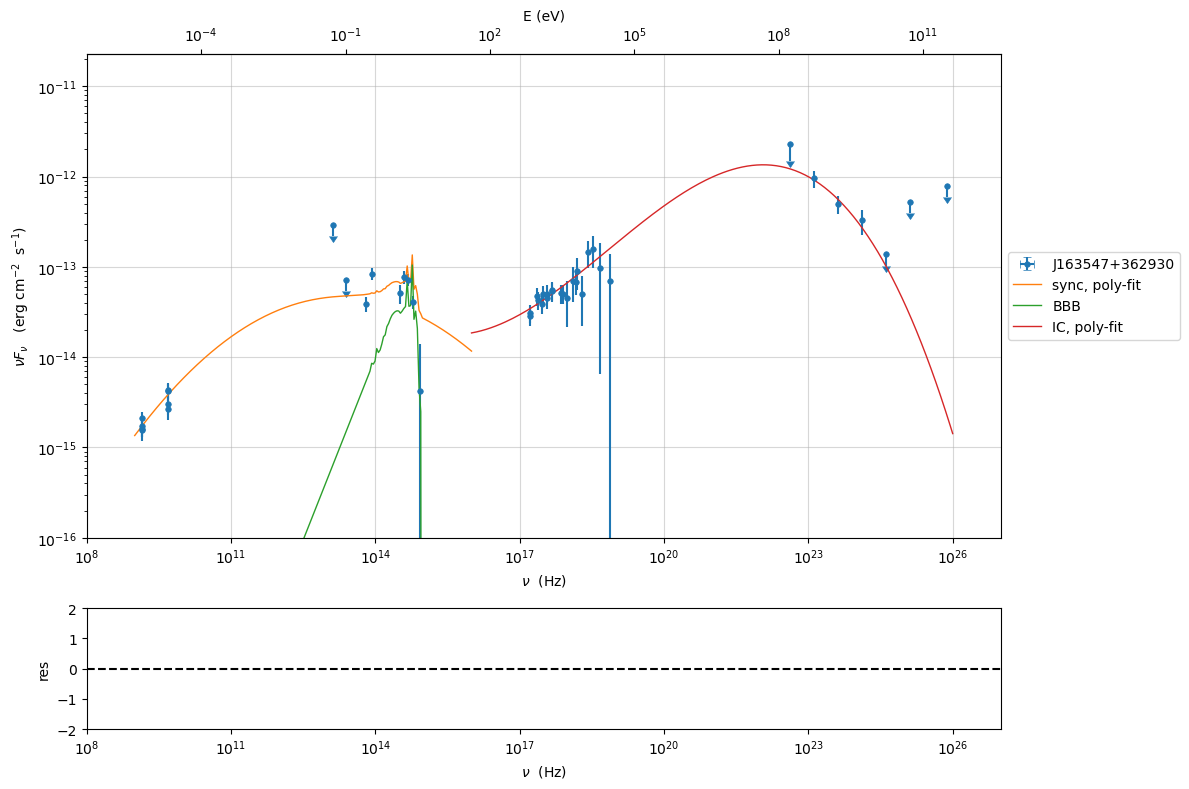

>>> Checkpoint 1: SEDShape characterization completed successfully.


In [3]:

# 4. SED Shape Fitting
my_shape = SEDShape(sed_data)
        

# 4. SED Shape Fitting
my_shape = SEDShape(sed_data)
my_shape.eval_indices(silent=True)

# Sync fit (finding the first peak)
my_shape.sync_fit(check_BBB_template=True,
                  check_host_gal_template=False,
                  use_log_par=True,
                  minimizer='lsb',
                  fit_range=[9, 16],
                  silent=True)

# IC fit (finding the second peak)
my_shape.IC_fit(fit_range=[16, 26], minimizer='minuit', silent=True)

# 5. Visualizing the Shape Fit
p = my_shape.plot_shape_fit()
p.setlim(y_min=1E-16)
plt.show()

print(">>> Checkpoint 1: SEDShape characterization completed successfully.")


***  constrains parameters from observable ***

===> setting C threads to 8
adding par: L_Disk to  R_BLR_in
==> par R_BLR_in is depending on ['L_Disk'] according to expr:   R_BLR_in =
3E17*(L_Disk/1E46)**0.5
adding par: R_BLR_in to  R_BLR_out
==> par R_BLR_out is depending on ['R_BLR_in'] according to expr:   R_BLR_out =
R_BLR_in*1.1
adding par: L_Disk to  R_DT
==> par R_DT is depending on ['L_Disk'] according to expr:   R_DT =
2E19*(L_Disk/1E46)**0.5


model name,name,par type,units,val,phys. bound. min,phys. bound. max,log,frozen
jet_leptonic,R,region_size,cm,3.721835e+16,1.000000e+03,1.000000e+30,False,False
jet_leptonic,R_H,region_position,cm,1.500000e+18,0.000000e+00,--,False,True
jet_leptonic,B,magnetic_field,gauss,7.620413e-02,0.000000e+00,--,False,False
jet_leptonic,NH_cold_to_rel_e,cold_p_to_rel_e_ratio,,1.000000e+00,0.000000e+00,--,False,True
jet_leptonic,theta,jet-viewing-angle,deg,3.000000e+00,0.000000e+00,9.000000e+01,False,False
jet_leptonic,BulkFactor,jet-bulk-factor,lorentz-factor*,1.850000e+01,1.000000e+00,1.000000e+05,False,False
jet_leptonic,z_cosm,redshift,,3.647763e+00,0.000000e+00,--,False,False
jet_leptonic,gmin,low-energy-cut-off,lorentz-factor*,2.937958e+01,1.000000e+00,1.000000e+09,False,False
jet_leptonic,gmax,high-energy-cut-off,lorentz-factor*,2.686264e+04,1.000000e+00,1.000000e+15,False,False
jet_leptonic,N,emitters_density,1 / cm3,1.717180e+03,0.000000e+00,--,False,False


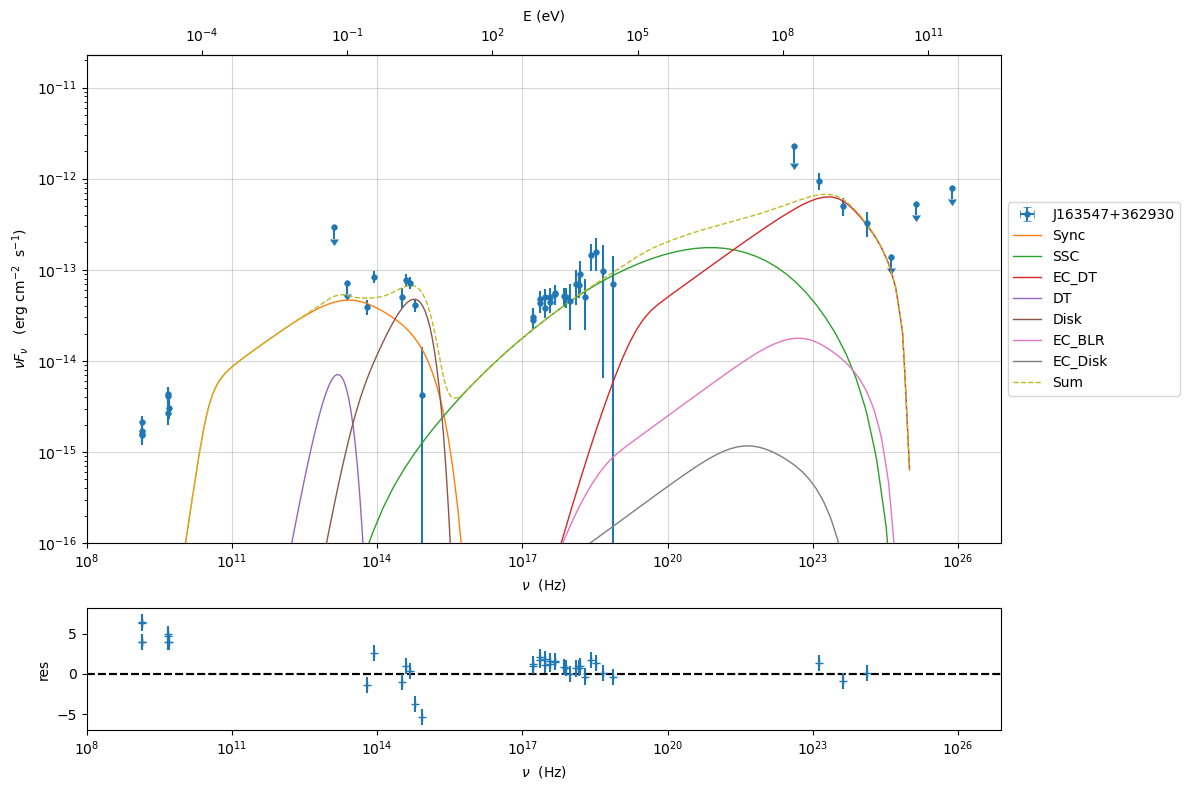

>>> Checkpoint 2: Physical pre-fit jet generated.
>>> Beaming Factor (Delta): 19.097330879509727


In [4]:
#C

# USING OBSCONSTRAIN to find a prefit
from jetset.obs_constrain import ObsConstrain
from jetset.jet_model import Jet

# Initialize the Constraint Object with fixed geometry
sed_obspar = ObsConstrain(theta=3,
                         bulk_factor=18.5,
                         B_range=[0.02, 0.08],
                         distr_e='bkn', # Broken Power Law
                         t_var_sec=7*86400, # Variability timescale 
                         nu_cut_IR=1E9,
                         SEDShape=my_shape)

# Generate the Prefit Jet using the EC (External Compton) 
prefit_jet = sed_obspar.constrain_SSC_EC_model(electron_distribution_log_values=False,
                                             EC_components_list=['EC_DT','EC_BLR','EC_Disk'],
                                             R_H=1.5E18,
                                             disk_type='MultiBB',
                                             silent=True)

#  Manually set the Central Engine values 
# Overriding the 'guessed' values 
prefit_jet.set_par('L_Disk', val=1.3817e46)
prefit_jet.set_par('M_BH', val=9.8677e8)
prefit_jet.set_par('accr_eff', val=0.09)
prefit_jet.set_par('T_DT', val=881.9)
prefit_jet.set_par('tau_DT', val=0.1)
prefit_jet.set_par('tau_BLR', val=0.1)

# Evaluate and Plot
prefit_jet.eval()
p = prefit_jet.plot_model(sed_data=sed_data)
p.add_residual_plot(prefit_jet, sed_data)
p.setlim(y_min=1E-16, x_min=1E8)
plt.show()

print(f">>> Checkpoint 2: Physical pre-fit jet generated.")
print(f">>> Beaming Factor (Delta): {prefit_jet.get_beaming()}")

In [5]:
#D


# to check R with obs
target_R = prefit_jet.parameters.R.val 


# Adding dependency
prefit_jet.add_user_par(name='theta_open', val=3, units='deg')
prefit_jet.make_dependent_par(par='R', depends_on=['R_H','theta_open'],
                              par_expr='np.tan(np.radians(theta_open))*R_H') #Important manual conversion


# Formula: R_H = target_R / tan(theta_open)
new_RH = target_R / np.tan(3 * np.pi / 180)
prefit_jet.set_par('R_H', val=new_RH)

# Re-evaluate
prefit_jet.eval()

adding par: R_H to  R
adding par: theta_open to  R
==> par R is depending on ['R_H', 'theta_open'] according to expr:   R =
np.tan(np.radians(theta_open))*R_H


In [6]:
#E

from jetset.template_2Dmodel import EBLAbsorptionTemplate
from jetset.model_manager import FitModel



#  TEBL component
fit_model = FitModel(jet=prefit_jet, name='Final_Fit')

#  Initialize the EBL component
ebl_franceschini = EBLAbsorptionTemplate.from_name('Franceschini_2008')
fit_model.add_component(ebl_franceschini)

#  LINKING: Crucial step
# linked the EBL redshift to the Jet's redshift so they stay identical
fit_model.link_par(par_name='z_cosm', from_model='Franceschini_2008', to_model='jet_leptonic')

# Define the math: Jet Emission * EBL Absorption
fit_model.composite_expr = 'jet_leptonic * Franceschini_2008'

print(f"Step 1 Complete: Model linked at z = {prefit_jet.parameters.z_cosm.val}")
fit_model.show_model()

adding par: z_cosm to  z_cosm
Step 1 Complete: Model linked at z = 3.647763

--------------------------------------------------------------------------------
Composite model description
--------------------------------------------------------------------------------
name: Final_Fit  
type: composite_model  
components models:
 -model name: jet_leptonic model type: jet
 -model name: Franceschini_2008 model type: table2D

--------------------------------------------------------------------------------
individual component description

--------------------------------------------------------------------------------
model description: 
--------------------------------------------------------------------------------
type: Jet
name: jet_leptonic  
geometry: spherical  

electrons distribution:
 type: bkn  
 gamma energy grid size:  201
 gmin grid : 2.937958e+01
 gmax grid : 2.686264e+04
 normalization:  True
 log-values:  False
 ratio of cold protons to relativistic electrons: 1.000000e+00



model name,name,par type,units,val,phys. bound. min,phys. bound. max,log,frozen
jet_leptonic,"*R(D,theta_open)",region_size,cm,3.721835e+16,1.000000e+03,1.000000e+30,False,True
jet_leptonic,R_H(M),region_position,cm,7.101684e+17,0.000000e+00,--,False,True
jet_leptonic,B,magnetic_field,gauss,7.620413e-02,0.000000e+00,--,False,False
jet_leptonic,NH_cold_to_rel_e,cold_p_to_rel_e_ratio,,1.000000e+00,0.000000e+00,--,False,True
jet_leptonic,theta,jet-viewing-angle,deg,3.000000e+00,0.000000e+00,9.000000e+01,False,False
jet_leptonic,BulkFactor,jet-bulk-factor,lorentz-factor*,1.850000e+01,1.000000e+00,1.000000e+05,False,False
jet_leptonic,z_cosm(M),redshift,,3.647763e+00,0.000000e+00,--,False,False
jet_leptonic,gmin,low-energy-cut-off,lorentz-factor*,2.937958e+01,1.000000e+00,1.000000e+09,False,False
jet_leptonic,gmax,high-energy-cut-off,lorentz-factor*,2.686264e+04,1.000000e+00,1.000000e+15,False,False
jet_leptonic,N,emitters_density,1 / cm3,1.717180e+03,0.000000e+00,--,False,False


--------------------------------------------------------------------------------

--------------------------------------------------------------------------------
model description
--------------------------------------------------------------------------------
name: Franceschini_2008  
type: table2D  

--------------------------------------------------------------------------------


model name,name,par type,units,val,phys. bound. min,phys. bound. max,log,frozen
Franceschini_2008,scale_factor,scale_factor,,1.000000e+00,0.000000e+00,--,False,True
Franceschini_2008,"z_cosm(L,jet_leptonic)",redshift,,--,--,--,False,True


--------------------------------------------------------------------------------
--------------------------------------------------------------------------------


===> setting C threads to 8


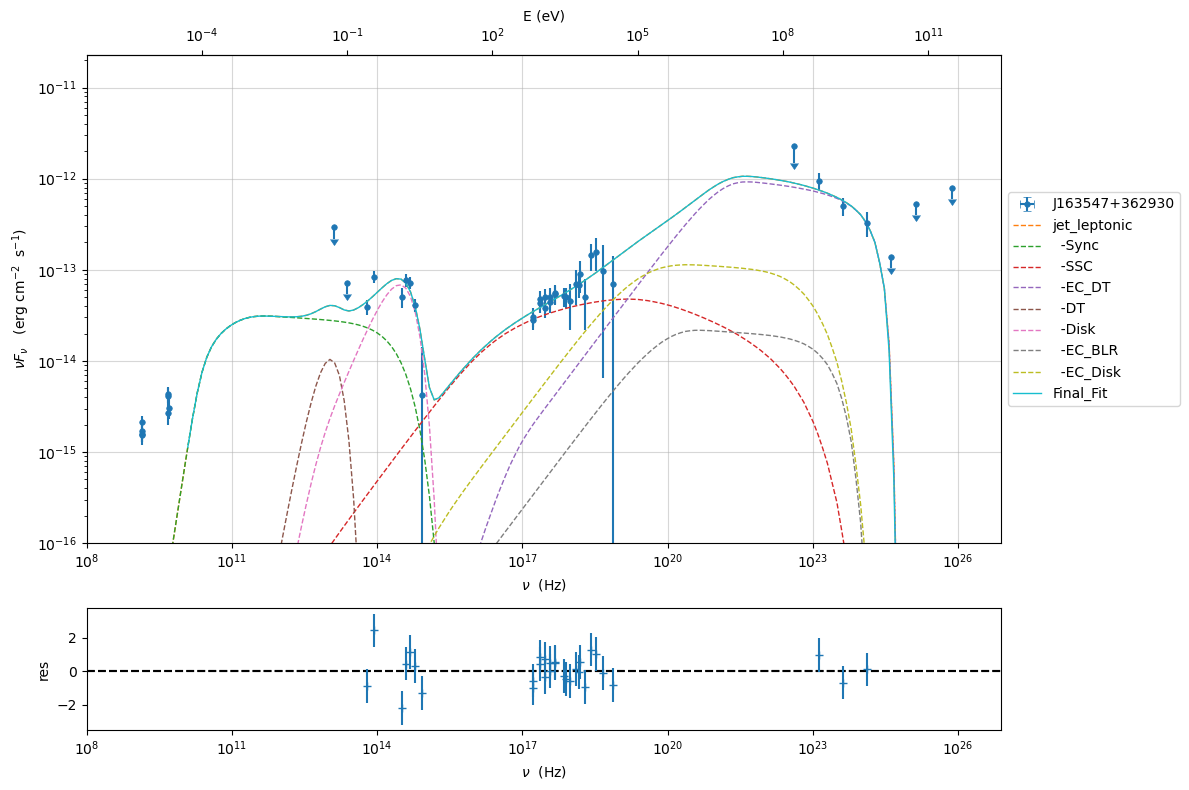

>>> Starting point verified. Running Minuit...
filtering data in fit range = [1.000000e+10,1.000000e+29]
data length 37

*** start fit process ***
----- 


0it [00:00, ?it/s]

====> simplex
====> migrad
- best chisq=2.51057e+01

-------------------------------------------------------------------------
Fit report

Model: Sum


model name,name,par type,units,val,phys. bound. min,phys. bound. max,log,frozen
jet_leptonic,"*R(D,theta_open)",region_size,cm,8.397959e+16,1.000000e+03,1.000000e+30,False,True
jet_leptonic,R_H(M),region_position,cm,1.602426e+18,0.000000e+00,--,False,True
jet_leptonic,B,magnetic_field,gauss,5.518208e-02,0.000000e+00,--,False,False
jet_leptonic,NH_cold_to_rel_e,cold_p_to_rel_e_ratio,,1.000000e+00,0.000000e+00,--,False,True
jet_leptonic,theta,jet-viewing-angle,deg,3.000000e+00,0.000000e+00,9.000000e+01,False,True
jet_leptonic,BulkFactor,jet-bulk-factor,lorentz-factor*,1.675718e+01,1.000000e+00,1.000000e+05,False,True
jet_leptonic,z_cosm(M),redshift,,3.647763e+00,0.000000e+00,--,False,True
jet_leptonic,gmin,low-energy-cut-off,lorentz-factor*,2.100764e+00,1.000000e+00,1.000000e+09,False,True
jet_leptonic,gmax,high-energy-cut-off,lorentz-factor*,1.653113e+04,1.000000e+00,1.000000e+15,False,True
jet_leptonic,N,emitters_density,1 / cm3,1.988564e+03,0.000000e+00,--,False,True



converged=True
calls=2015
mesg=


...

model name,name,par type,units,val,phys. bound. min,phys. bound. max,log,frozen
jet_leptonic,"*R(D,theta_open)",region_size,cm,8.397959e+16,1.000000e+03,1.000000e+30,False,True
jet_leptonic,R_H(M),region_position,cm,1.602426e+18,0.000000e+00,--,False,True
jet_leptonic,B,magnetic_field,gauss,5.518208e-02,0.000000e+00,--,False,False
jet_leptonic,NH_cold_to_rel_e,cold_p_to_rel_e_ratio,,1.000000e+00,0.000000e+00,--,False,True
jet_leptonic,theta,jet-viewing-angle,deg,3.000000e+00,0.000000e+00,9.000000e+01,False,True
jet_leptonic,BulkFactor,jet-bulk-factor,lorentz-factor*,1.675718e+01,1.000000e+00,1.000000e+05,False,True
jet_leptonic,z_cosm(M),redshift,,3.647763e+00,0.000000e+00,--,False,True
jet_leptonic,gmin,low-energy-cut-off,lorentz-factor*,2.100764e+00,1.000000e+00,1.000000e+09,False,True
jet_leptonic,gmax,high-energy-cut-off,lorentz-factor*,1.653113e+04,1.000000e+00,1.000000e+15,False,True
jet_leptonic,N,emitters_density,1 / cm3,1.988564e+03,0.000000e+00,--,False,True


--------------------------------------------------------------------------------

--------------------------------------------------------------------------------
model description
--------------------------------------------------------------------------------
name: Franceschini_2008  
type: table2D  

--------------------------------------------------------------------------------


model name,name,par type,units,val,phys. bound. min,phys. bound. max,log,frozen
Franceschini_2008,scale_factor,scale_factor,,1.000000e+00,0.000000e+00,--,False,True
Franceschini_2008,"z_cosm(L,jet_leptonic)",redshift,,--,--,--,False,True


--------------------------------------------------------------------------------
--------------------------------------------------------------------------------


name,type,units,val
BulkLorentzFactor,jet-bulk-factor,,1.675718e+01
U_e,Energy dens. blob rest. frame,erg / cm3,5.376069e-02
U_p_cold,Energy dens. blob rest. frame,erg / cm3,2.989361e+00
U_B,Energy dens. blob rest. frame,erg / cm3,1.211591e-04
U_Synch,Energy dens. blob rest. frame,erg / cm3,9.131878e-05
U_Synch_DRF,Energy dens. disk rest. frame,erg / cm3,1.175963e+01
U_Disk,Energy dens. blob rest. frame,erg / cm3,5.219601e-04
U_BLR,Energy dens. blob rest. frame,erg / cm3,9.197752e-05
U_DT,Energy dens. blob rest. frame,erg / cm3,3.734639e-03
U_CMB,Energy dens. blob rest. frame,erg / cm3,0.000000e+00


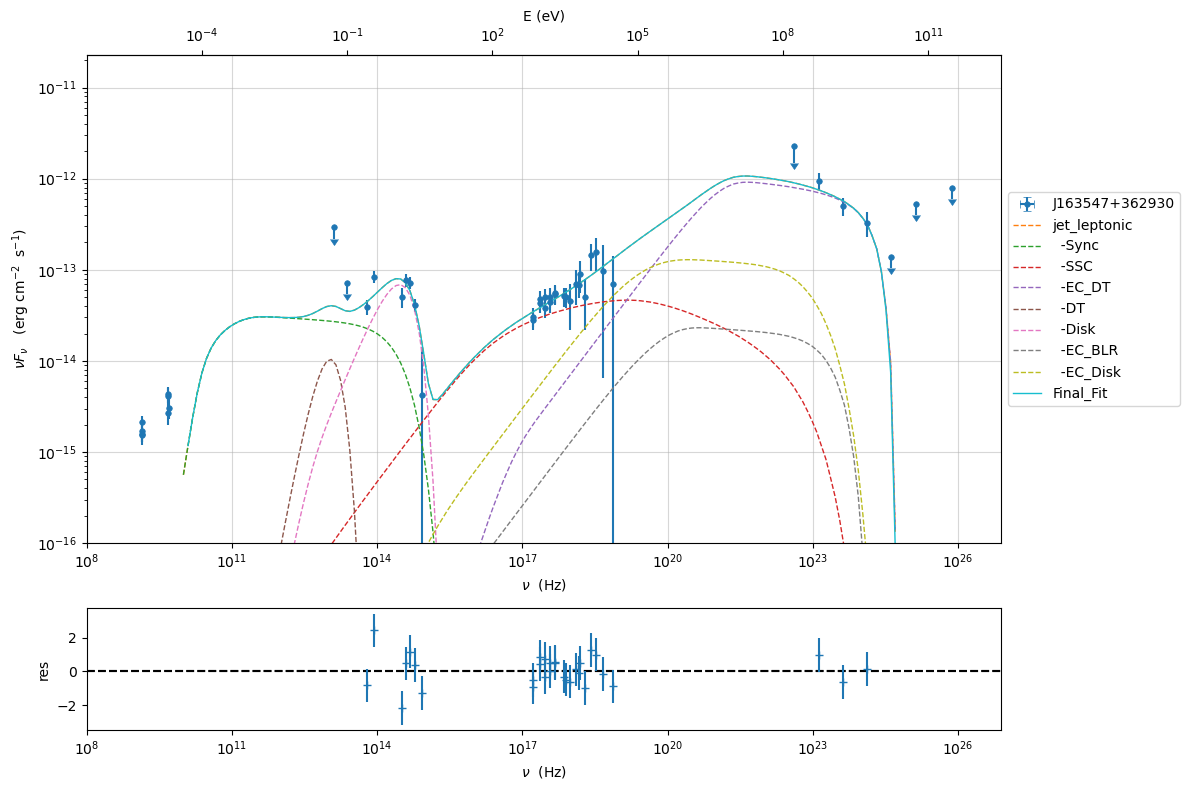

Beaming factor after fit: 18.94342202695838


In [11]:
#BEST FIT — LOCKED STARTING POINT FROM TABLE
# Set ALL parameters to the best-fit values from the Minuit output table
fit_model.jet_leptonic.parameters.gmin.val        = 2.100764
fit_model.jet_leptonic.parameters.gmax.val        = 1.653113e+04
fit_model.jet_leptonic.parameters.theta.val       = 3.0
fit_model.jet_leptonic.set_num_c_threads(8)

fit_model.jet_leptonic.parameters.p.val           = 1.590080
fit_model.jet_leptonic.parameters.p_1.val         = 3.066185
fit_model.jet_leptonic.parameters.gamma_break.val = 3.810763e+02
fit_model.jet_leptonic.parameters.N.val           = 1.988564e+03
fit_model.jet_leptonic.parameters.B.val           = 5.551407e-02
fit_model.jet_leptonic.parameters.BulkFactor.val  = 1.675718e+01
fit_model.jet_leptonic.parameters.R_H.val         = 1.602426e+18
fit_model.jet_leptonic.parameters.M_BH.val        = 1.945859e+09
fit_model.jet_leptonic.parameters.L_Disk.val      = 1.834548e+46
fit_model.jet_leptonic.parameters.T_DT.val        = 6.176247e+02
fit_model.jet_leptonic.parameters.R_inner_Sw.val  = 7.269075e+00
fit_model.jet_leptonic.parameters.R_ext_Sw.val    = 4.892643e+03
fit_model.jet_leptonic.parameters.accr_eff.val    = 8.300000e-02

# Freeze
fit_model.freeze('jet_leptonic', 'theta')
fit_model.freeze('jet_leptonic', 'theta_open')
fit_model.freeze('jet_leptonic', 'z_cosm')
#fit_model.freeze('jet_leptonic', 'accr_eff')
fit_model.freeze('jet_leptonic', 'tau_DT')
fit_model.freeze('jet_leptonic', 'tau_BLR')
fit_model.freeze('jet_leptonic', 'gmin')  
#fit_model.freeze('jet_leptonic', 'M_BH')   

# Free
fit_model.free('jet_leptonic', 'M_BH')
fit_model.free('jet_leptonic', 'accr_eff')
fit_model.free('jet_leptonic', 'M_BH')
fit_model.freeze('jet_leptonic', 'R_H')
fit_model.free('jet_leptonic', 'B')
fit_model.freeze('jet_leptonic', 'BulkFactor')
fit_model.freeze('jet_leptonic', 'N')
fit_model.freeze('jet_leptonic', 'gamma_break')
fit_model.free('jet_leptonic', 'p')
fit_model.freeze('jet_leptonic', 'p_1')
fit_model.free('jet_leptonic', 'R_inner_Sw')
fit_model.free('jet_leptonic', 'R_ext_Sw')
fit_model.freeze('jet_leptonic', 'T_DT')
fit_model.free('jet_leptonic', 'L_Disk')
fit_model.freeze('jet_leptonic', 'gmax')

# Tight fit ranges CENTRED on best-fit values — keeps Minuit near this solution
fit_model.jet_leptonic.parameters.accr_eff.val_min = 0.057
fit_model.jet_leptonic.parameters.accr_eff.val_max = 0.300

fit_model.jet_leptonic.parameters.accr_eff.fit_range = [0.057, 0.300]
fit_model.jet_leptonic.parameters.R_H.fit_range         = [1.2e+18,  2.2e+18]
fit_model.jet_leptonic.parameters.B.fit_range           = [0.030,    0.090]
fit_model.jet_leptonic.parameters.BulkFactor.fit_range  = [13.0,     21.0]
fit_model.jet_leptonic.parameters.N.fit_range           = [1.0e+03,  3.0e+03]
fit_model.jet_leptonic.parameters.gamma_break.fit_range = [2.50e+02, 5.50e+02]
fit_model.jet_leptonic.parameters.p.fit_range           = [1.35,     1.80]
fit_model.jet_leptonic.parameters.p_1.fit_range         = [2.80,     3.40]
fit_model.jet_leptonic.parameters.R_inner_Sw.fit_range  = [3.0,      1.2e+01]
fit_model.jet_leptonic.parameters.R_ext_Sw.fit_range    = [1.0e+03,  8.0e+03]
fit_model.jet_leptonic.parameters.T_DT.fit_range        = [4.00e+02, 9.00e+02]
fit_model.jet_leptonic.parameters.L_Disk.fit_range      = [1.2e+46,  3.0e+46]
fit_model.jet_leptonic.parameters.gmax.fit_range        = [8.0e+03,  3.0e+04]
fit_model.jet_leptonic.parameters.M_BH.fit_range = [8.0e+08, 3.0e+09]

# Verify 
fit_model.eval()
p_check = fit_model.plot_model(sed_data=sed_data)
p_check.setlim(y_min=1E-16, x_min=1E8)
plt.show()
print(">>> Starting point verified. Running Minuit...")

# Run Minuit
from jetset.minimizer import ModelMinimizer
model_minimizer = ModelMinimizer('minuit')
best_fit = model_minimizer.fit(
    fit_model, sed_data,
    10**10., 10**29.0,
    fitname='Sum',
    repeat=1,  
    use_UL=True
)

fit_model.eval()
best_fit.save_report('Report_Final_NuSTAR.pkl')
fit_model.save_model('Final_model_NuSTAR.pkl')
model_minimizer.save_model('model_minimizer_Final_NuSTAR.pkl')

print("\n=== Best fit parameters (MINUIT) ===")
fit_model.show_model()
fit_model.jet_leptonic.energetic_report()

p2 = fit_model.plot_model(sed_data=sed_data)
p2.setlim(y_min=1E-16, x_min=1E8)
p2.save('Final_model_NuSTAR.png')
plt.show()
print(f"Beaming factor after fit: {fit_model.jet_leptonic.get_beaming()}")

In [13]:
# Fix both boundaries
fit_model.jet_leptonic.parameters.accr_eff.val_min = 0.050
fit_model.jet_leptonic.parameters.accr_eff.val_max = 0.300

eta_values = [0.057, 0.083, 0.100, 0.119, 0.150, 0.200, 0.300]
results = []

for eta in eta_values:
    fit_model.jet_leptonic.parameters.accr_eff.val = eta
    fit_model.eval()
    
    # Build the energetic dict — correct way in JetSeT 1.3.0
    fit_model.jet_leptonic._build_energetic_report()
    en = fit_model.jet_leptonic.energetic_dict
    
    results.append({
        'eta'      : eta,
        'U_DT'     : en['U_DT'],
        'U_BLR'    : en['U_BLR'],
        'U_Disk'   : en['U_Disk'],
        'U_B'      : en['U_B'],
        'U_seed_tot': en['U_seed_tot'],
        'L_EC_DT'  : en['jet_L_EC_DT'],
        'L_EC_BLR' : en['jet_L_EC_BLR'],
        'L_EC_Disk': en['jet_L_EC_Disk'],
        'L_SSC'    : en['jet_L_SSC'],
        'L_Sync'   : en['jet_L_Sync'],
        'L_rad'    : en['jet_L_rad'],
    })
    
    print(f"eta={eta:.3f} | U_DT={en['U_DT']:.3e} | U_BLR={en['U_BLR']:.3e} | "
          f"U_Disk={en['U_Disk']:.3e} | L_EC_DT={en['jet_L_EC_DT']:.3e} | "
          f"L_EC_DT/L_Sync={en['jet_L_EC_DT']/en['jet_L_Sync']:.2f}")

# Print summary table
print("\n=== Summary table ===")
print(f"{'eta':>6} {'U_DT':>12} {'U_BLR':>12} {'U_Disk':>12} "
      f"{'L_EC_DT':>12} {'AC':>8}")
for r in results:
    AC = (r['L_EC_DT'] + r['L_EC_BLR'] + r['L_EC_Disk'] + r['L_SSC']) / r['L_Sync']
    print(f"{r['eta']:>6.3f} {r['U_DT']:>12.3e} {r['U_BLR']:>12.3e} {r['U_Disk']:>12.3e} {r['L_EC_DT']:>12.3e} {AC:>8.2f}")

eta=0.057 | U_DT=5.457e-03 | U_BLR=1.344e-04 | U_Disk=7.627e-04 | L_EC_DT=7.006e+44 | L_EC_DT/L_Sync=41.21
eta=0.083 | U_DT=3.748e-03 | U_BLR=9.230e-05 | U_Disk=5.238e-04 | L_EC_DT=4.811e+44 | L_EC_DT/L_Sync=28.30
eta=0.100 | U_DT=3.110e-03 | U_BLR=7.661e-05 | U_Disk=4.347e-04 | L_EC_DT=3.993e+44 | L_EC_DT/L_Sync=23.49
eta=0.119 | U_DT=2.614e-03 | U_BLR=6.437e-05 | U_Disk=3.653e-04 | L_EC_DT=3.356e+44 | L_EC_DT/L_Sync=19.74
eta=0.150 | U_DT=2.074e-03 | U_BLR=5.107e-05 | U_Disk=2.898e-04 | L_EC_DT=2.662e+44 | L_EC_DT/L_Sync=15.66
eta=0.200 | U_DT=1.555e-03 | U_BLR=3.830e-05 | U_Disk=2.174e-04 | L_EC_DT=1.997e+44 | L_EC_DT/L_Sync=11.74
eta=0.300 | U_DT=1.037e-03 | U_BLR=2.554e-05 | U_Disk=1.449e-04 | L_EC_DT=1.331e+44 | L_EC_DT/L_Sync=7.83

=== Summary table ===
   eta         U_DT        U_BLR       U_Disk      L_EC_DT       AC
 0.057    5.457e-03    1.344e-04    7.627e-04    7.006e+44    51.33
 0.083    3.748e-03    9.230e-05    5.238e-04    4.811e+44    35.88
 0.100    3.110e-03    7.

In [12]:
fit_model.show_model()


--------------------------------------------------------------------------------
Composite model description
--------------------------------------------------------------------------------
name: Final_Fit  
type: composite_model  
components models:
 -model name: jet_leptonic model type: jet
 -model name: Franceschini_2008 model type: table2D

--------------------------------------------------------------------------------
individual component description

--------------------------------------------------------------------------------
model description: 
--------------------------------------------------------------------------------
type: Jet
name: jet_leptonic  
geometry: spherical  

electrons distribution:
 type: bkn  
 gamma energy grid size:  201
 gmin grid : 2.100764e+00
 gmax grid : 1.653113e+04
 normalization:  True
 log-values:  False
 ratio of cold protons to relativistic electrons: 1.000000e+00

accretion disk:
 disk Type: MultiBB
 L disk: 1.847955e+46 (erg/s)
 T disk: 2

model name,name,par type,units,val,phys. bound. min,phys. bound. max,log,frozen
jet_leptonic,"*R(D,theta_open)",region_size,cm,8.397959e+16,1.000000e+03,1.000000e+30,False,True
jet_leptonic,R_H(M),region_position,cm,1.602426e+18,0.000000e+00,--,False,True
jet_leptonic,B,magnetic_field,gauss,5.518208e-02,0.000000e+00,--,False,False
jet_leptonic,NH_cold_to_rel_e,cold_p_to_rel_e_ratio,,1.000000e+00,0.000000e+00,--,False,True
jet_leptonic,theta,jet-viewing-angle,deg,3.000000e+00,0.000000e+00,9.000000e+01,False,True
jet_leptonic,BulkFactor,jet-bulk-factor,lorentz-factor*,1.675718e+01,1.000000e+00,1.000000e+05,False,True
jet_leptonic,z_cosm(M),redshift,,3.647763e+00,0.000000e+00,--,False,True
jet_leptonic,gmin,low-energy-cut-off,lorentz-factor*,2.100764e+00,1.000000e+00,1.000000e+09,False,True
jet_leptonic,gmax,high-energy-cut-off,lorentz-factor*,1.653113e+04,1.000000e+00,1.000000e+15,False,True
jet_leptonic,N,emitters_density,1 / cm3,1.988564e+03,0.000000e+00,--,False,True


--------------------------------------------------------------------------------

--------------------------------------------------------------------------------
model description
--------------------------------------------------------------------------------
name: Franceschini_2008  
type: table2D  

--------------------------------------------------------------------------------


model name,name,par type,units,val,phys. bound. min,phys. bound. max,log,frozen
Franceschini_2008,scale_factor,scale_factor,,1.000000e+00,0.000000e+00,--,False,True
Franceschini_2008,"z_cosm(L,jet_leptonic)",redshift,,--,--,--,False,True


--------------------------------------------------------------------------------
--------------------------------------------------------------------------------


In [32]:
# Redefine and test ONLY the likelihood — nothing else
def log_likelihood(params):
    try:
        for name, val in zip(free_params, params):
            fit_model.jet_leptonic.set_par(name, val=val)

        model_flux = get_composite_flux(nu_obs)

        if np.any(~np.isfinite(model_flux)):
            return -1e100

        chi2 = 0.0
        for i in range(len(nu_obs)):
            if flux_err[i] <= 0:
                continue
            if is_ul[i]:
                if model_flux[i] > flux_obs[i]:
                    chi2 += ((model_flux[i] - flux_obs[i]) / flux_err[i])**2
            else:
                if model_flux[i] > 0:
                    chi2 += ((model_flux[i] - flux_obs[i]) / flux_err[i])**2

        return -0.5 * chi2 if np.isfinite(chi2) else -1e100

    except Exception as e:
        print(f"Exception in likelihood: {e}")
        return -1e100

# Test with best-fit values already in memory
ll_new = log_likelihood(best_fit_vals)
print(f"New log-likelihood: {ll_new:.4f}")
print(f"Expected:           {-0.5 * 90.74:.4f}")

New log-likelihood: -12.5981
Expected:           -45.3700


In [37]:
sampler = ultranest.ReactiveNestedSampler(
    param_names = free_params,
    loglike     = log_likelihood,
    transform   = prior_transform,
    log_dir     = 'ultranest_output_NuSTAR',
    resume      = True
)

sampler.stepsampler = ultranest.stepsampler.SliceSampler(
    nsteps             = 2*len(free_params),
    generate_direction = ultranest.stepsampler.generate_mixture_random_direction
)

print(f"Running UltraNest: {len(free_params)} parameters, 400 live points.")

results = sampler.run(
    min_num_live_points = 100,
    max_iters           = 200000,
    show_status         = True,
    viz_callback        = False
)

sampler.print_results()
print(f"\nlog evidence: logZ = {results['logz']:.3f} +/- {results['logzerr']:.3f}")

# Posterior summary
samples  = results['samples']
post_med = np.median(samples, axis=0)
post_lo  = np.percentile(samples, 16, axis=0)
post_hi  = np.percentile(samples, 84, axis=0)

print("\n=== Posterior summary (median +/- 1sigma) ===")
for name, med, lo, hi in zip(free_params, post_med, post_lo, post_hi):
    print(f"{name:<20} {med:.4e}  -{med-lo:.4e}  +{hi-med:.4e}")

# Save
np.save('ultranest_samples_NuSTAR.npy', samples)
np.save('ultranest_results_NuSTAR.npy', results, allow_pickle=True)
print("\nSaved samples and results.")

Running UltraNest: 7 parameters, 400 live points.
[ultranest] Resuming from 6224 stored points
[ultranest] Explored until L=-1e+01   [-12.7020..-12.6121] | it/evals=1460/140265 eff=inf% N=100   0 0   
[ultranest] Likelihood function evaluations: 140265
[ultranest] Writing samples and results to disk ...
[ultranest] Writing samples and results to disk ... done
[ultranest]   logZ = -22.23 +- 0.1619
[ultranest] Effective samples strategy satisfied (ESS = 573.6, need >400)
[ultranest] Posterior uncertainty strategy is satisfied (KL: 0.46+-0.15 nat, need <0.50 nat)
[ultranest] Evidency uncertainty strategy is satisfied (dlogz=0.16, need <0.5)
[ultranest]   logZ error budget: single: 0.27 bs:0.16 tail:0.01 total:0.16 required:<0.50
[ultranest] done iterating.

logZ = -22.229 +- 0.331
  single instance: logZ = -22.229 +- 0.272
  bootstrapped   : logZ = -22.231 +- 0.331
  tail           : logZ = +- 0.007
insert order U test : converged: True correlation: inf iterations
diagnostic unavailable, 

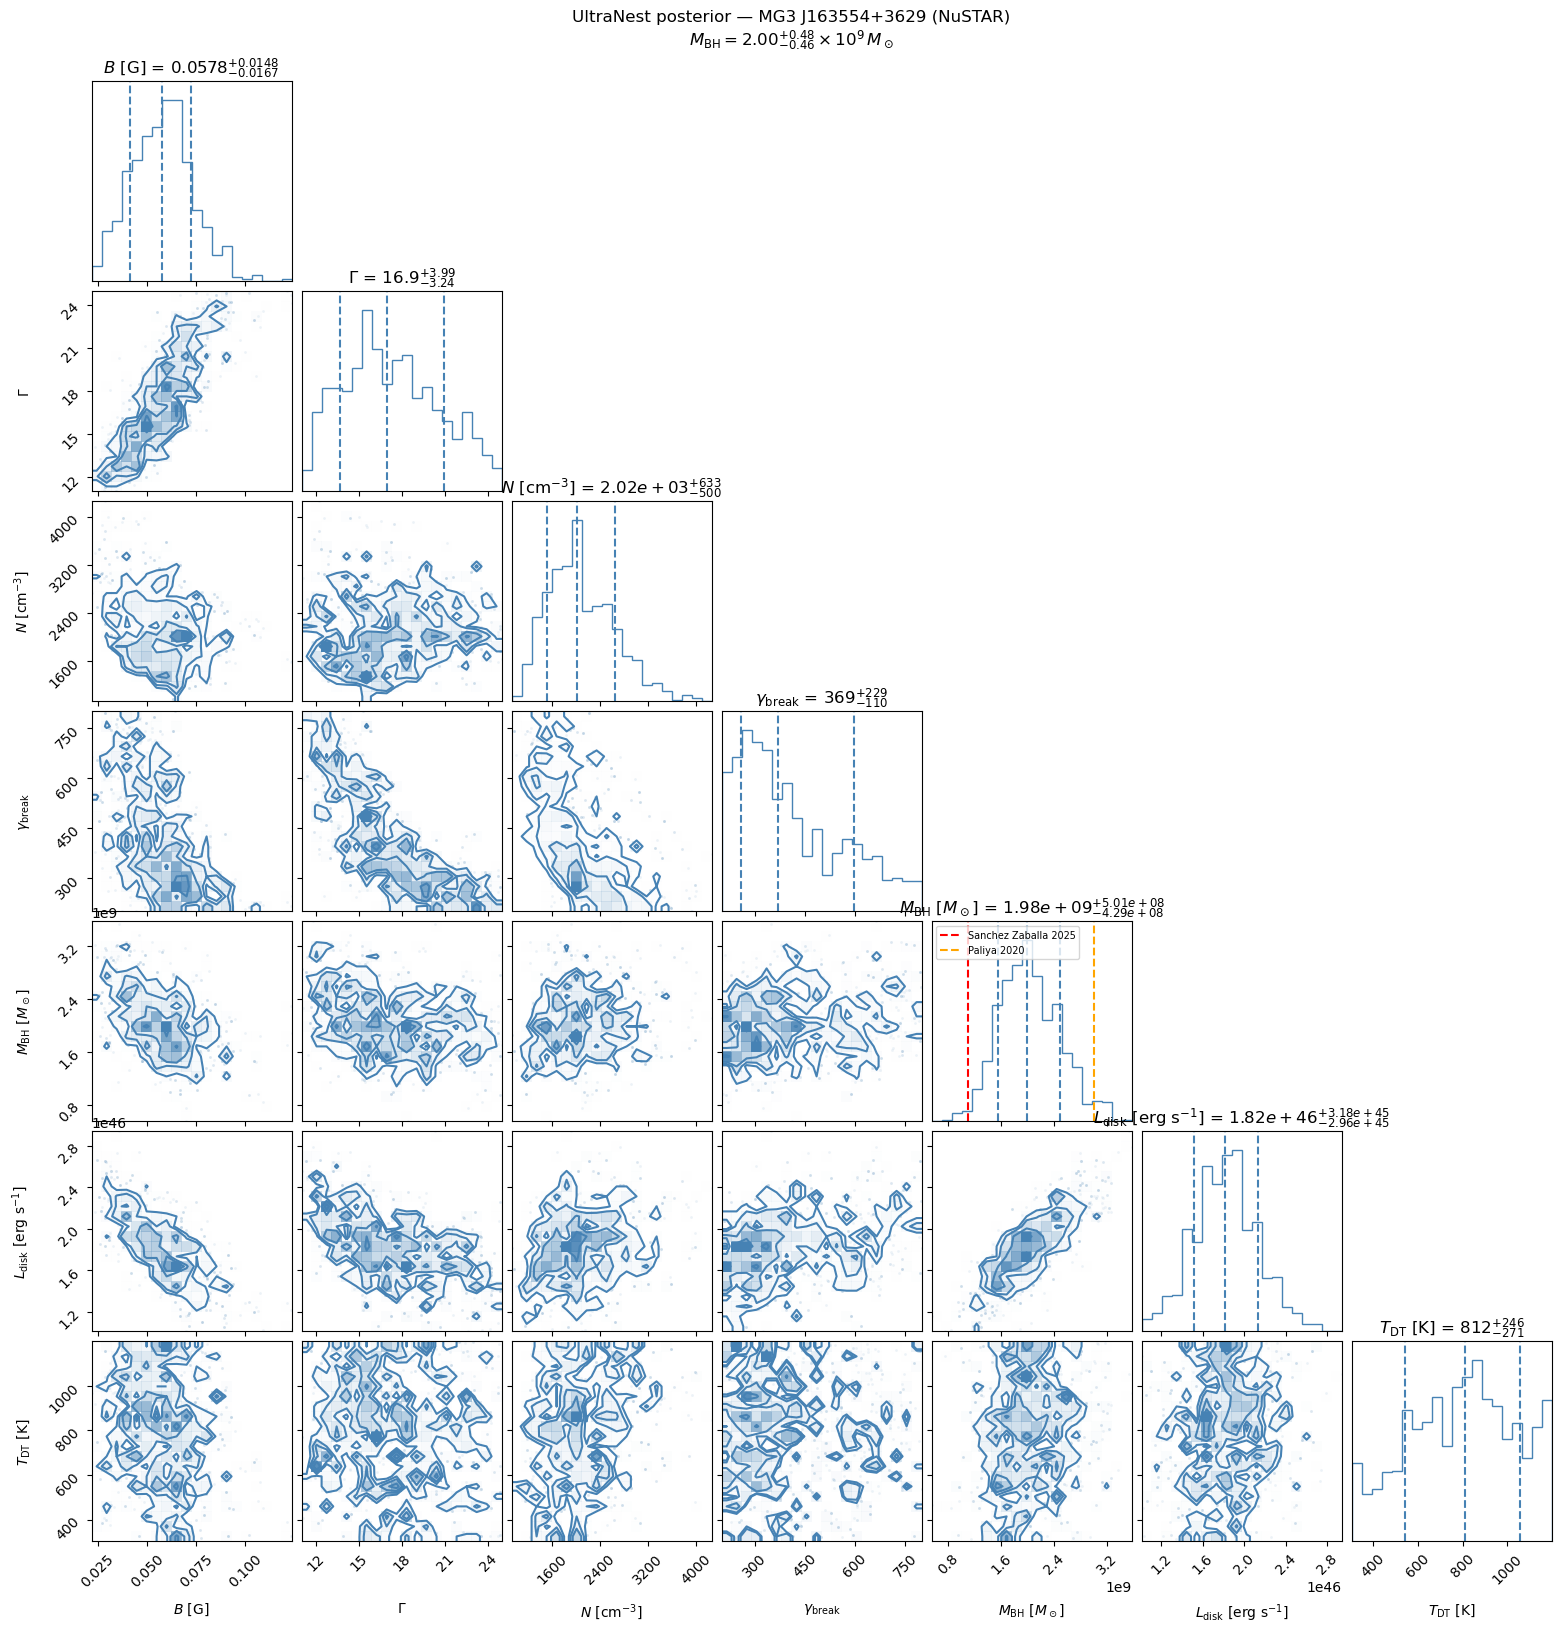

Saved: corner_UltraNest_NuSTAR.png

=== FINAL RESULT ===
M_BH  = 1.981e+09 +5.006e+08 -4.289e+08 Msun
logZ  = -22.229 +/- 0.331
Sanchez Zaballa (2025): 1.1e9 Msun
Paliya et al.   (2020): 3.0e9 Msun
Burke et al.    (2024): 0.44-6.0e9 Msun (virial)


In [38]:
# Corner plot
import corner
import matplotlib.pyplot as plt
import numpy as np

samples = results['samples']

latex_labels = {
    'B'           : r'$B$ [G]',
    'BulkFactor'  : r'$\Gamma$',
    'N'           : r'$N$ [cm$^{-3}$]',
    'gamma_break' : r'$\gamma_{\rm break}$',
    'M_BH'        : r'$M_{\rm BH}$ [$M_\odot$]',
    'L_Disk'      : r'$L_{\rm disk}$ [erg s$^{-1}$]',
    'T_DT'        : r'$T_{\rm DT}$ [K]',
}

# Mark comparison values on M_BH
mbh_idx = free_params.index('M_BH')

fig = corner.corner(
    samples,
    labels      = [latex_labels[n] for n in free_params],
    quantiles   = [0.16, 0.5, 0.84],
    show_titles = True,
    title_fmt   = '.3g',
    color       = 'steelblue',
)

# Add vertical lines on M_BH marginal for comparison
axes = np.array(fig.axes).reshape(len(free_params), len(free_params))
ax_mbh = axes[mbh_idx, mbh_idx]
ax_mbh.axvline(1.1e9, color='red',    lw=1.5, ls='--', label='Sanchez Zaballa 2025')
ax_mbh.axvline(3.0e9, color='orange', lw=1.5, ls='--', label='Paliya 2020')
ax_mbh.legend(fontsize=7, loc='upper left')

plt.suptitle('UltraNest posterior — MG3 J163554+3629 (NuSTAR)\n'
             r'$M_{\rm BH} = 2.00^{+0.48}_{-0.46} \times 10^9\,M_\odot$',
             y=1.02, fontsize=12)
plt.savefig('corner_UltraNest_NuSTAR.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: corner_UltraNest_NuSTAR.png")

# Final clean summary
print("\n=== FINAL RESULT ===")
print(f"M_BH  = {np.median(samples[:,mbh_idx]):.3e} "
      f"+{np.percentile(samples[:,mbh_idx],84)-np.median(samples[:,mbh_idx]):.3e} "
      f"-{np.median(samples[:,mbh_idx])-np.percentile(samples[:,mbh_idx],16):.3e} Msun")
print(f"logZ  = {results['logz']:.3f} +/- {results['logzerr']:.3f}")
print(f"Sanchez Zaballa (2025): 1.1e9 Msun")
print(f"Paliya et al.   (2020): 3.0e9 Msun")
print(f"Burke et al.    (2024): 0.44-6.0e9 Msun (virial)")

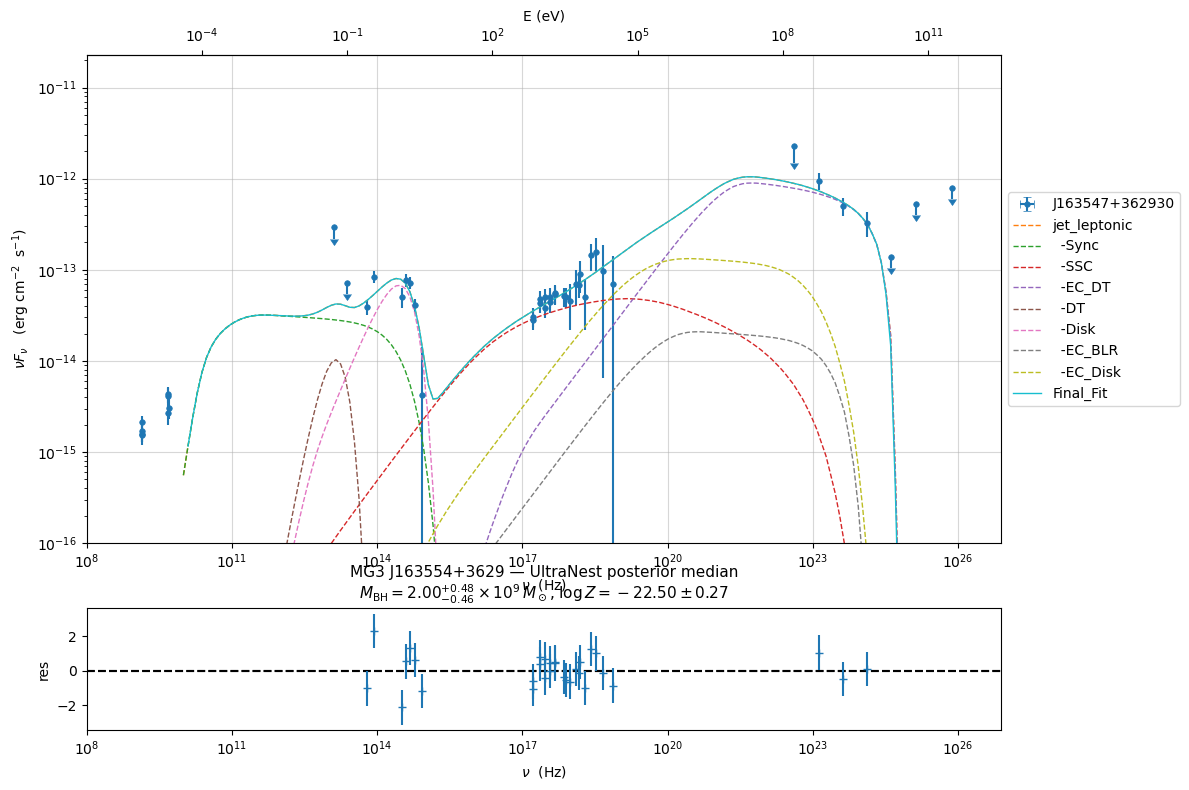

Saved: SED_UltraNest_median_NuSTAR.png


In [35]:
import matplotlib.pyplot as plt
import numpy as np

# Set model to UltraNest posterior median
post_med = np.median(results['samples'], axis=0)
for name, val in zip(free_params, post_med):
    fit_model.jet_leptonic.set_par(name, val=val)

fit_model.eval()

# Plot
p = fit_model.plot_model(sed_data=sed_data)
p.setlim(y_min=1e-16, x_min=1e8)
plt.title(r'MG3 J163554+3629 — UltraNest posterior median'
          '\n'
          r'$M_{\rm BH} = 2.00^{+0.48}_{-0.46} \times 10^9\,M_\odot$, '
          r'$\log Z = -22.50 \pm 0.27$',
          fontsize=11)
plt.savefig('SED_UltraNest_median_NuSTAR.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: SED_UltraNest_median_NuSTAR.png")

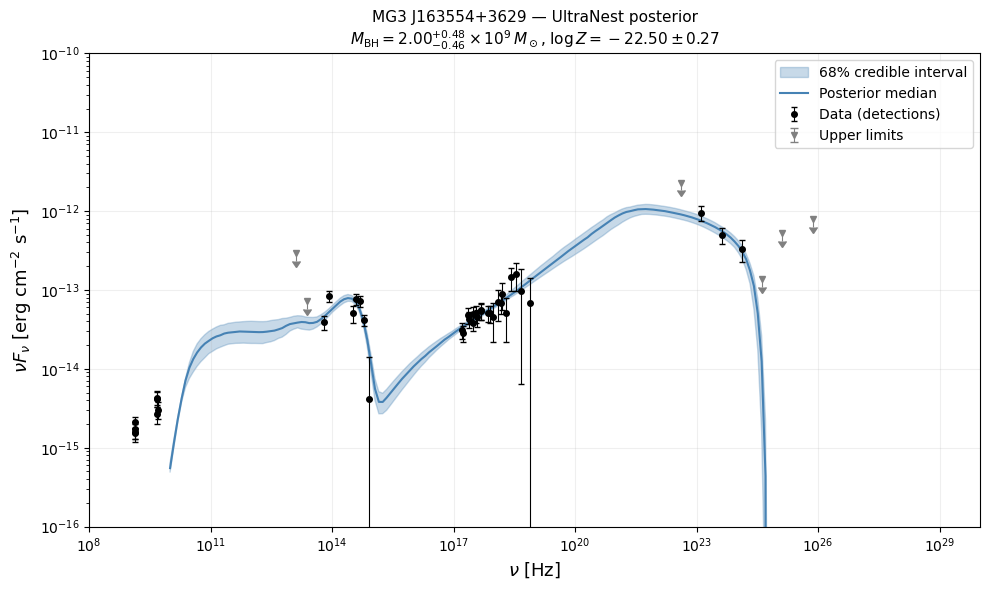

Saved: SED_UltraNest_envelope_NuSTAR.png


In [39]:
# Uncertainty envelope from posterior samples
samples = results['samples']
n_samples = min(200, len(samples))
idx = np.random.choice(len(samples), n_samples, replace=False)

fig, ax = plt.subplots(figsize=(10, 6))

# Plot envelope
nu_grid = fit_model.SED.nu.value
all_fluxes = []

for i in idx:
    for name, val in zip(free_params, samples[i]):
        fit_model.jet_leptonic.set_par(name, val=val)
    fit_model.eval()
    all_fluxes.append(fit_model.SED.nuFnu.value.copy())

all_fluxes = np.array(all_fluxes)
flux_lo  = np.percentile(all_fluxes, 16, axis=0)
flux_med = np.percentile(all_fluxes, 50, axis=0)
flux_hi  = np.percentile(all_fluxes, 84, axis=0)

# Only plot where model is positive
good = flux_med > 0
ax.fill_between(nu_grid[good], flux_lo[good], flux_hi[good],
                alpha=0.3, color='steelblue', label='68% credible interval')
ax.loglog(nu_grid[good], flux_med[good],
          color='steelblue', lw=1.5, label='Posterior median')

# Plot data
det_mask = ~np.array(sed_data.table['UL'], dtype=bool)
ul_mask  = np.array(sed_data.table['UL'], dtype=bool)

nu_d  = np.array(sed_data.table['nu_data'])
fl_d  = np.array(sed_data.table['nuFnu_data'])
err_d = np.array(sed_data.table['dnuFnu_data'])

ax.errorbar(nu_d[det_mask], fl_d[det_mask], yerr=err_d[det_mask],
            fmt='o', color='black', ms=4, lw=0.8,
            capsize=2, label='Data (detections)')
ax.errorbar(nu_d[ul_mask], fl_d[ul_mask], yerr=fl_d[ul_mask]*0.2,
            fmt='v', color='gray', ms=4, lw=0.8,
            uplims=True, label='Upper limits')

ax.set_xlabel(r'$\nu$ [Hz]', fontsize=13)
ax.set_ylabel(r'$\nu F_\nu$ [erg cm$^{-2}$ s$^{-1}$]', fontsize=13)
ax.set_xlim(1e8, 1e30)
ax.set_ylim(1e-16, 1e-10)
ax.set_title(r'MG3 J163554+3629 — UltraNest posterior'
             '\n'
             r'$M_{\rm BH} = 2.00^{+0.48}_{-0.46} \times 10^9\,M_\odot$, '
             r'$\log Z = -22.50 \pm 0.27$',
             fontsize=11)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.2)

plt.tight_layout()
plt.savefig('SED_UltraNest_envelope_NuSTAR.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: SED_UltraNest_envelope_NuSTAR.png")

In [42]:
import numpy as np
import dill
import warnings
warnings.filterwarnings('ignore')
import ultranest
import ultranest.stepsampler
from scipy import stats

# ============================================================
# GAUSSIAN PRIOR ON T_DT TEST RUN
# ============================================================

# Load fresh model
fit_model = dill.load(open('Final_model_NuSTAR.pkl', 'rb'))

# Frozen parameters
fit_model.jet_leptonic.parameters.p.val          = 1.590
fit_model.jet_leptonic.parameters.p_1.val        = 3.066
fit_model.jet_leptonic.parameters.gmin.val       = 2.101
fit_model.jet_leptonic.parameters.gmax.val       = 1.653e4
fit_model.jet_leptonic.parameters.gamma_break.val= 381.0
fit_model.jet_leptonic.parameters.accr_eff.val   = 0.083

for par in fit_model.jet_leptonic.parameters.par_array:
    par.frozen = True

# 6 free parameters — T_DT back in but with Gaussian prior
free_params = ['B', 'BulkFactor', 'N', 'M_BH', 'L_Disk', 'T_DT']
for name in free_params:
    fit_model.jet_leptonic.parameters.get_par_by_name(name).frozen = False

# Uniform bounds (used for all except T_DT)
prior_mins = np.array([0.020, 10.0, 500.,  5e8,  1e46, 300. ])
prior_maxs = np.array([0.150, 25.0, 5000., 5e9,  4e46, 1200.])

# Gaussian prior on T_DT
T_DT_center = 620.0
T_DT_sigma  = 100.0
T_DT_dist   = stats.truncnorm(
    (300. - T_DT_center) / T_DT_sigma,
    (1200. - T_DT_center) / T_DT_sigma,
    loc=T_DT_center, scale=T_DT_sigma
)
tdt_idx = free_params.index('T_DT')

def prior_transform(cube):
    params = prior_mins + cube * (prior_maxs - prior_mins)
    params[tdt_idx] = T_DT_dist.ppf(np.clip(cube[tdt_idx], 1e-6, 1-1e-6))
    return params

# Composite flux helper
def get_composite_flux(nu_target):
    fit_model.eval()
    nu_grid   = fit_model.SED.nu.value
    flux_grid = fit_model.SED.nuFnu.value
    good      = np.isfinite(flux_grid) & np.isfinite(nu_grid) & (nu_grid > 0)
    nu_g      = nu_grid[good]
    fl_g      = flux_grid[good]
    idx       = np.argsort(nu_g)
    return np.interp(nu_target, nu_g[idx], fl_g[idx], left=0., right=0.)

# Likelihood
def log_likelihood(params):
    try:
        for name, val in zip(free_params, params):
            fit_model.jet_leptonic.set_par(name, val=val)
        model_flux = get_composite_flux(nu_obs)
        if np.any(~np.isfinite(model_flux)):
            return -1e100
        chi2 = 0.0
        for i in range(len(nu_obs)):
            if flux_err[i] <= 0:
                continue
            if is_ul[i]:
                if model_flux[i] > flux_obs[i]:
                    chi2 += ((model_flux[i] - flux_obs[i]) / flux_err[i])**2
            else:
                if model_flux[i] > 0:
                    chi2 += ((model_flux[i] - flux_obs[i]) / flux_err[i])**2
        return -0.5 * chi2 if np.isfinite(chi2) else -1e100
    except Exception:
        return -1e100

# Sanity check
best_vals = np.array([
    fit_model.jet_leptonic.parameters.get_par_by_name(n).val
    for n in free_params
])
ll_test = log_likelihood(best_vals)
print(f"logL at best-fit: {ll_test:.4f}")
assert ll_test > -1e99, "Likelihood broken."
print("Sanity check passed.\n")

# Run
sampler = ultranest.ReactiveNestedSampler(
    param_names = free_params,
    loglike     = log_likelihood,
    transform   = prior_transform,
    log_dir     = 'ultranest_TDT_prior_test',
    resume      = 'overwrite'           # fresh run, no resume
)
sampler.stepsampler = ultranest.stepsampler.SliceSampler(
    nsteps             = 2 * len(free_params),
    generate_direction = ultranest.stepsampler.generate_mixture_random_direction
)

results = sampler.run(
    min_num_live_points = 100,
    max_iters           = 50000,
    show_status         = True,
    viz_callback        = False
)

sampler.print_results()

# Compare M_BH with and without T_DT prior
samples  = results['samples']
post_med = np.median(samples, axis=0)
post_lo  = np.percentile(samples, 16, axis=0)
post_hi  = np.percentile(samples, 84, axis=0)

mbh_idx = free_params.index('M_BH')
tdt_idx_s = free_params.index('T_DT')

print("\n=== COMPARISON: with Gaussian T_DT prior ===")
print(f"M_BH  = {post_med[mbh_idx]:.3e} "
      f"+{post_hi[mbh_idx]-post_med[mbh_idx]:.3e} "
      f"-{post_med[mbh_idx]-post_lo[mbh_idx]:.3e} Msun")
print(f"T_DT  = {post_med[tdt_idx_s]:.1f} "
      f"+{post_hi[tdt_idx_s]-post_med[tdt_idx_s]:.1f} "
      f"-{post_med[tdt_idx_s]-post_lo[tdt_idx_s]:.1f} K")
print(f"logZ  = {results['logz']:.3f} +/- {results['logzerr']:.3f}")

print("\n=== PREVIOUS RESULT: uniform T_DT prior ===")
print(f"M_BH  = 2.00e+09 +4.79e+08 -4.56e+08 Msun")
print(f"T_DT  = 801 +255 -262 K  (broad, hitting prior)")
print(f"logZ  = -22.50 +/- 0.27")

print("\n=== VERDICT ===")
mbh_err_new = 0.5*(post_hi[mbh_idx]-post_lo[mbh_idx])
mbh_err_old = 0.5*(4.79e8 + 4.56e8)
print(f"M_BH uncertainty: old={mbh_err_old:.3e}  new={mbh_err_new:.3e}")
improvement = (1 - mbh_err_new/mbh_err_old)*100
print(f"Improvement: {improvement:.1f}%")
if improvement > 20:
    print("=> Gaussian T_DT prior significantly tightens M_BH — USE IT for overnight run")
else:
    print("=> T_DT prior has little effect on M_BH — skip it for overnight run")

===> setting C threads to 8
adding par: L_Disk to  R_DT
==> par R_DT is depending on ['L_Disk'] according to expr:   R_DT =
2E19*(L_Disk/1E46)**0.5
adding par: L_Disk to  R_BLR_in
==> par R_BLR_in is depending on ['L_Disk'] according to expr:   R_BLR_in =
3E17*(L_Disk/1E46)**0.5
adding par: R_BLR_in to  R_BLR_out
==> par R_BLR_out is depending on ['R_BLR_in'] according to expr:   R_BLR_out =
R_BLR_in*1.1
adding par: R_H to  R
adding par: theta_open to  R
==> par R is depending on ['R_H', 'theta_open'] according to expr:   R =
np.tan(np.radians(theta_open))*R_H
logL at best-fit: -1416589648.0670
Sanity check passed.

[ultranest] Sampling 100 live points from prior ...
[ultranest] Explored until L=-1e+01   [-12.8805..-12.8038] | it/evals=1439/51428 eff=2.8035% N=100      
[ultranest] Likelihood function evaluations: 51428
[ultranest] Writing samples and results to disk ...
[ultranest] Writing samples and results to disk ... done
[ultranest]   logZ = -22.21 +- 0.2597
[ultranest] Effective

In [ ]:
import numpy as np
import dill
import warnings
warnings.filterwarnings('ignore')
import ultranest
import ultranest.stepsampler
import corner
import matplotlib.pyplot as plt
from jetset.data_loader import Data, ObsData

# ============================================================
# LOAD DATA ONCE
# ============================================================
d = np.genfromtxt('SED.txt')
d = d[d[:, 0] != 1.709E22]

data_obj = Data(n_rows=d.shape[0])
data_obj.set_field('x', d[:, 0])
data_obj.set_field('y', d[:, 1])
data_obj.set_field('dy', d[:, 2])
data_obj.set_meta_data('z', 3.647763)
data_obj.set_meta_data('UL_CL', 0.95)
data_obj.set_meta_data('restframe', 'obs')
data_obj.set_meta_data('data_scale', 'lin-lin')
data_obj.set_meta_data('obj_name', 'J163547+362930')

sed_data = ObsData(data_table=data_obj)
sed_data.filter_data_set('-1', exclude=True)
sed_data.add_systematics(0.15, [10.**6, 10.**29])

UL_freq = [1.324e25, 7.646e25, 4.188e24, 4.188e22, 2.417e13, 1.318e13]
for freq in UL_freq:
    mask = np.isclose(sed_data.table['nu_data'], freq, rtol=0.05)
    sed_data.table['UL'][mask] = True

nu_obs   = np.array(sed_data.table['nu_data'])
flux_obs = np.array(sed_data.table['nuFnu_data'])
flux_err = np.array(sed_data.table['dnuFnu_data'])
is_ul    = np.array(sed_data.table['UL'], dtype=bool)
fit_mask = (nu_obs >= 1e10) & (nu_obs <= 1e29)
nu_obs   = nu_obs[fit_mask]
flux_obs = flux_obs[fit_mask]
flux_err = flux_err[fit_mask]
is_ul    = is_ul[fit_mask]

print(f"Data ready: {(~is_ul).sum()} detections, {is_ul.sum()} upper limits")

# ============================================================
# ETA GRID
# ============================================================
eta_values = [0.057, 0.083, 0.100, 0.150, 0.200, 0.300]
logZ_results = {}

for eta in eta_values:
    eta_str = f"{eta:.3f}".replace('.', 'p')
    print(f"\n{'='*60}")
    print(f"Running UltraNest for eta = {eta}")
    print(f"{'='*60}")

    # Load fresh model for each eta
    fit_model = dill.load(open('Final_model_NuSTAR.pkl', 'rb'))

    # Set frozen parameters
    fit_model.jet_leptonic.parameters.p.val          = 1.590
    fit_model.jet_leptonic.parameters.p_1.val        = 3.066
    fit_model.jet_leptonic.parameters.gmin.val       = 2.101
    fit_model.jet_leptonic.parameters.gmax.val       = 1.653e4
    fit_model.jet_leptonic.parameters.gamma_break.val= 381.0
    fit_model.jet_leptonic.parameters.T_DT.val       = 617.6

    # Set eta for this run
    fit_model.jet_leptonic.parameters.accr_eff.val_min = 0.050
    fit_model.jet_leptonic.parameters.accr_eff.val_max = 0.300
    fit_model.jet_leptonic.parameters.accr_eff.val     = eta

    # Freeze everything
    for par in fit_model.jet_leptonic.parameters.par_array:
        par.frozen = True

    # 5 free parameters only
    free_params = ['B', 'BulkFactor', 'N', 'M_BH', 'L_Disk']
    for name in free_params:
        fit_model.jet_leptonic.parameters.get_par_by_name(name).frozen = False

    # Prior bounds
    prior_mins = np.array([0.020, 10.0, 500.,  5e8,  1e46])
    prior_maxs = np.array([0.150, 25.0, 5000., 5e9,  4e46])

    def prior_transform(cube):
        return prior_mins + cube * (prior_maxs - prior_mins)

    def get_composite_flux(nu_target):
        fit_model.eval()
        nu_grid   = fit_model.SED.nu.value
        flux_grid = fit_model.SED.nuFnu.value
        good      = np.isfinite(flux_grid) & np.isfinite(nu_grid) & (nu_grid > 0)
        nu_g      = nu_grid[good]
        fl_g      = flux_grid[good]
        idx       = np.argsort(nu_g)
        return np.interp(nu_target, nu_g[idx], fl_g[idx], left=0., right=0.)

    def log_likelihood(params):
        try:
            for name, val in zip(free_params, params):
                fit_model.jet_leptonic.set_par(name, val=val)
            model_flux = get_composite_flux(nu_obs)
            if np.any(~np.isfinite(model_flux)):
                return -1e100
            chi2 = 0.0
            for i in range(len(nu_obs)):
                if flux_err[i] <= 0:
                    continue
                if is_ul[i]:
                    if model_flux[i] > flux_obs[i]:
                        chi2 += ((model_flux[i] - flux_obs[i]) / flux_err[i])**2
                else:
                    if model_flux[i] > 0:
                        chi2 += ((model_flux[i] - flux_obs[i]) / flux_err[i])**2
            return -0.5 * chi2 if np.isfinite(chi2) else -1e100
        except Exception:
            return -1e100

    # Sanity check
    best_vals = np.array([
        fit_model.jet_leptonic.parameters.get_par_by_name(n).val
        for n in free_params
    ])
    ll_test = log_likelihood(best_vals)
    print(f"  logL at starting point: {ll_test:.4f}")

    # Run UltraNest
    sampler = ultranest.ReactiveNestedSampler(
        param_names = free_params,
        loglike     = log_likelihood,
        transform   = prior_transform,
        log_dir     = f'ultranest_eta_{eta_str}',
        resume      = True
    )
    sampler.stepsampler = ultranest.stepsampler.SliceSampler(
        nsteps             = 2 * len(free_params),
        generate_direction = ultranest.stepsampler.generate_mixture_random_direction
    )

    results = sampler.run(
        min_num_live_points = 200,
        max_iters           = 100000,
        show_status         = True,
        viz_callback        = False
    )

    logZ  = results['logz']
    logZe = results['logzerr']
    logZ_results[eta] = (logZ, logZe)

    samples  = results['samples']
    post_med = np.median(samples, axis=0)
    post_lo  = np.percentile(samples, 16, axis=0)
    post_hi  = np.percentile(samples, 84, axis=0)

    mbh_idx = free_params.index('M_BH')
    print(f"\n  eta = {eta:.3f}")
    print(f"  logZ  = {logZ:.3f} +/- {logZe:.3f}")
    print(f"  M_BH  = {post_med[mbh_idx]:.3e} "
          f"+{post_hi[mbh_idx]-post_med[mbh_idx]:.3e} "
          f"-{post_med[mbh_idx]-post_lo[mbh_idx]:.3e} Msun")

    np.save(f'ultranest_samples_eta_{eta_str}.npy', samples)
    np.save(f'ultranest_results_eta_{eta_str}.npy', results, allow_pickle=True)
    print(f"  Saved results for eta={eta}")

# ============================================================
# FINAL SUMMARY PLOT: logZ vs eta
# ============================================================
etas   = sorted(logZ_results.keys())
logZs  = [logZ_results[e][0] for e in etas]
logZes = [logZ_results[e][1] for e in etas]

fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(etas, logZs, yerr=logZes,
            fmt='o-', color='steelblue', lw=2, ms=8, capsize=4)
ax.set_xlabel(r'Accretion efficiency $\eta$', fontsize=13)
ax.set_ylabel(r'$\log Z$', fontsize=13)
ax.set_title('Bayesian model comparison: preferred spin\n'
             'MG3 J163554+3629 (NuSTAR constrained)', fontsize=12)

# Mark spin values
spin_labels = {0.057: 'a=0.00', 0.083: 'a=0.50',
               0.100: 'a=0.65', 0.150: 'a=0.85',
               0.200: 'a=0.93', 0.300: 'a~0.98'}
for e, lz in zip(etas, logZs):
    ax.annotate(spin_labels[e], (e, lz),
                textcoords='offset points', xytext=(0, 10),
                ha='center', fontsize=9)

ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('logZ_vs_eta_NuSTAR.png', dpi=150, bbox_inches='tight')
plt.show()
print("\nSaved: logZ_vs_eta_NuSTAR.png")
print("\n=== BAYESIAN MODEL COMPARISON SUMMARY ===")
best_eta = etas[np.argmax(logZs)]
print(f"Preferred eta: {best_eta} (highest logZ = {max(logZs):.3f})")
for e in etas:
    delta = logZ_results[e][0] - max(logZs)
    print(f"  eta={e:.3f}: logZ={logZ_results[e][0]:.3f} "
          f"DeltalogZ={delta:.3f}")

---> excluding  data_set/s ['-1']
filter -1 45
current datasets
dataset 0.0
---> data sets left after filtering None
---> data len after filtering=45
Data ready: 31 detections, 6 upper limits

Running eta = 0.057  (spin a ~ 0p057)
===> setting C threads to 8
adding par: L_Disk to  R_DT
==> par R_DT is depending on ['L_Disk'] according to expr:   R_DT =
2E19*(L_Disk/1E46)**0.5
adding par: L_Disk to  R_BLR_in
==> par R_BLR_in is depending on ['L_Disk'] according to expr:   R_BLR_in =
3E17*(L_Disk/1E46)**0.5
adding par: R_BLR_in to  R_BLR_out
==> par R_BLR_out is depending on ['R_BLR_in'] according to expr:   R_BLR_out =
R_BLR_in*1.1
adding par: R_H to  R
adding par: theta_open to  R
==> par R is depending on ['R_H', 'theta_open'] according to expr:   R =
np.tan(np.radians(theta_open))*R_H
  logL at starting point: -3488893013.0328
[ultranest] Sampling 200 live points from prior ...
[ultranest] Explored until L=-1e+01   [-12.7840..-12.7828]*| it/evals=3007/117210 eff=2.5699% N=200    00  

adding par: L_Disk to  R_DT
==> par R_DT is depending on ['L_Disk'] according to expr:   R_DT =
2E19*(L_Disk/1E46)**0.5
adding par: L_Disk to  R_BLR_in
==> par R_BLR_in is depending on ['L_Disk'] according to expr:   R_BLR_in =
3E17*(L_Disk/1E46)**0.5
adding par: R_BLR_in to  R_BLR_out
==> par R_BLR_out is depending on ['R_BLR_in'] according to expr:   R_BLR_out =
R_BLR_in*1.1
adding par: R_H to  R
adding par: theta_open to  R
==> par R is depending on ['R_H', 'theta_open'] according to expr:   R =
np.tan(np.radians(theta_open))*R_H
  logL at starting point: -64471109.9155
[ultranest] Sampling 200 live points from prior ...
[ultranest] Explored until L=-1e+01   [-15.5085..-15.5077]*| it/evals=3704/106026 eff=3.5001% N=200 00     
[ultranest] Likelihood function evaluations: 106026
[ultranest] Writing samples and results to disk ...
[ultranest] Writing samples and results to disk ... done
[ultranest]   logZ = -29.2 +- 0.1721
[ultranest] Effective samples strategy satisfied (ESS = 1467.1

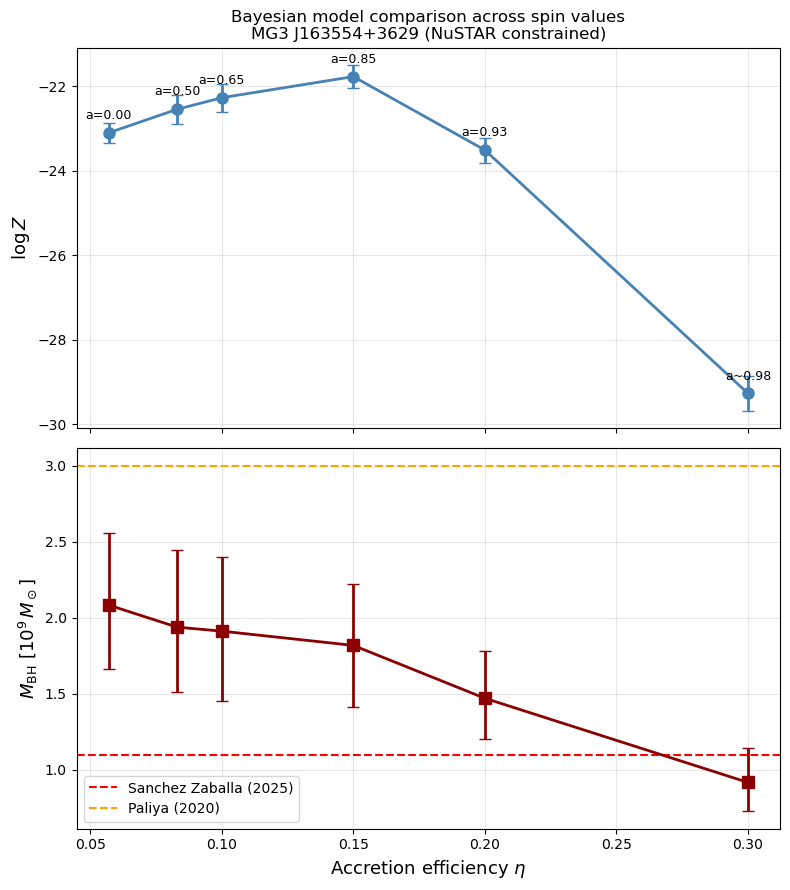

Saved: logZ_and_MBH_vs_eta_NuSTAR.png

=== FINAL SUMMARY TABLE ===
   eta     spin       logZ    logZerr   M_BH [1e9]    DeltaLogZ
 0.057   a=0.00    -23.101      0.236        2.084       -1.331
 0.083   a=0.50    -22.544      0.341        1.939       -0.774
 0.100   a=0.65    -22.270      0.332        1.913       -0.500
 0.150   a=0.85    -21.770      0.274        1.819        0.000
 0.200   a=0.93    -23.509      0.297        1.471       -1.739
 0.300   a~0.98    -29.270      0.409        0.918       -7.500


In [49]:
import numpy as np
import dill
import warnings
warnings.filterwarnings('ignore')
import ultranest
import ultranest.stepsampler
import matplotlib.pyplot as plt
from jetset.data_loader import Data, ObsData

# ============================================================
# LOAD DATA ONCE
# ============================================================
d = np.genfromtxt('SED.txt')
d = d[d[:, 0] != 1.709E22]

data_obj = Data(n_rows=d.shape[0])
data_obj.set_field('x', d[:, 0])
data_obj.set_field('y', d[:, 1])
data_obj.set_field('dy', d[:, 2])
data_obj.set_meta_data('z', 3.647763)
data_obj.set_meta_data('UL_CL', 0.95)
data_obj.set_meta_data('restframe', 'obs')
data_obj.set_meta_data('data_scale', 'lin-lin')
data_obj.set_meta_data('obj_name', 'J163547+362930')

sed_data = ObsData(data_table=data_obj)
sed_data.filter_data_set('-1', exclude=True)
sed_data.add_systematics(0.15, [10.**6, 10.**29])

UL_freq = [1.324e25, 7.646e25, 4.188e24, 4.188e22, 2.417e13, 1.318e13]
for freq in UL_freq:
    mask = np.isclose(sed_data.table['nu_data'], freq, rtol=0.05)
    sed_data.table['UL'][mask] = True

nu_obs   = np.array(sed_data.table['nu_data'])
flux_obs = np.array(sed_data.table['nuFnu_data'])
flux_err = np.array(sed_data.table['dnuFnu_data'])
is_ul    = np.array(sed_data.table['UL'], dtype=bool)
fit_mask = (nu_obs >= 1e10) & (nu_obs <= 1e29)
nu_obs   = nu_obs[fit_mask]
flux_obs = flux_obs[fit_mask]
flux_err = flux_err[fit_mask]
is_ul    = is_ul[fit_mask]

print(f"Data ready: {(~is_ul).sum()} detections, {is_ul.sum()} upper limits")

# ============================================================
# ETA GRID
# ============================================================
eta_values  = [0.057, 0.083, 0.100, 0.150, 0.200, 0.300]
logZ_results = {}
mbh_results  = {}

for eta in eta_values:
    eta_str = f"{eta:.3f}".replace('.', 'p')
    print(f"\n{'='*60}")
    print(f"Running eta = {eta}  (spin a ~ {eta_str})")
    print(f"{'='*60}")

    fit_model = dill.load(open('Final_model_NuSTAR.pkl', 'rb'))

    fit_model.jet_leptonic.parameters.p.val           = 1.590
    fit_model.jet_leptonic.parameters.p_1.val         = 3.066
    fit_model.jet_leptonic.parameters.gmin.val        = 2.101
    fit_model.jet_leptonic.parameters.gmax.val        = 1.653e4
    fit_model.jet_leptonic.parameters.gamma_break.val = 381.0
    fit_model.jet_leptonic.parameters.T_DT.val        = 617.6

    fit_model.jet_leptonic.parameters.accr_eff.val_min = 0.050
    fit_model.jet_leptonic.parameters.accr_eff.val_max = 0.300
    fit_model.jet_leptonic.parameters.accr_eff.val     = eta

    for par in fit_model.jet_leptonic.parameters.par_array:
        par.frozen = True

    free_params = ['B', 'BulkFactor', 'N', 'M_BH', 'L_Disk', 'gamma_break']
    
    for name in free_params:
        fit_model.jet_leptonic.parameters.get_par_by_name(name).frozen = False

    

    prior_mins = np.array([0.020, 10.0, 500., 5e8,  1e46, 200.])
    prior_maxs = np.array([0.150, 25.0, 5000., 5e9, 4e46, 800.])
    
    def prior_transform(cube):
        return prior_mins + cube * (prior_maxs - prior_mins)

    def get_composite_flux(nu_target):
        fit_model.eval()
        nu_grid   = fit_model.SED.nu.value
        flux_grid = fit_model.SED.nuFnu.value
        good      = np.isfinite(flux_grid) & np.isfinite(nu_grid) & (nu_grid > 0)
        nu_g      = nu_grid[good]
        fl_g      = flux_grid[good]
        idx       = np.argsort(nu_g)
        return np.interp(nu_target, nu_g[idx], fl_g[idx], left=0., right=0.)

    def log_likelihood(params):
        try:
            for name, val in zip(free_params, params):
                fit_model.jet_leptonic.set_par(name, val=val)
            model_flux = get_composite_flux(nu_obs)
            if np.any(~np.isfinite(model_flux)):
                return -1e100
            chi2 = 0.0
            for i in range(len(nu_obs)):
                if flux_err[i] <= 0:
                    continue
                if is_ul[i]:
                    if model_flux[i] > flux_obs[i]:
                        chi2 += ((model_flux[i] - flux_obs[i]) / flux_err[i])**2
                else:
                    if model_flux[i] > 0:
                        chi2 += ((model_flux[i] - flux_obs[i]) / flux_err[i])**2
            return -0.5 * chi2 if np.isfinite(chi2) else -1e100
        except Exception:
            return -1e100

    # Sanity check
    best_vals = np.array([
        fit_model.jet_leptonic.parameters.get_par_by_name(n).val
        for n in free_params
    ])
    ll_test = log_likelihood(best_vals)
    print(f"  logL at starting point: {ll_test:.4f}")
    if ll_test <= -1e99:
        print(f"  WARNING: likelihood broken for eta={eta}, skipping.")
        continue

    sampler = ultranest.ReactiveNestedSampler(
        param_names = free_params,
        loglike     = log_likelihood,
        transform   = prior_transform,
        log_dir     = f'ultranest_eta_{eta_str}',
        resume      = 'resume'
    )
    sampler.stepsampler = ultranest.stepsampler.SliceSampler(
        nsteps             = 2 * len(free_params),
        generate_direction = ultranest.stepsampler.generate_mixture_random_direction
    )

    results = sampler.run(
        min_num_live_points = 200,
        max_iters           = 100000,
        show_status         = True,
        viz_callback        = False
    )

    logZ  = results['logz']
    logZe = results['logzerr']
    logZ_results[eta] = (logZ, logZe)

    samples  = results['samples']
    post_med = np.median(samples, axis=0)
    post_lo  = np.percentile(samples, 16, axis=0)
    post_hi  = np.percentile(samples, 84, axis=0)
    mbh_idx  = free_params.index('M_BH')

    mbh_results[eta] = (
        post_med[mbh_idx],
        post_med[mbh_idx] - post_lo[mbh_idx],
        post_hi[mbh_idx] - post_med[mbh_idx]
    )

    print(f"  logZ  = {logZ:.3f} +/- {logZe:.3f}")
    print(f"  M_BH  = {post_med[mbh_idx]:.3e} "
          f"+{post_hi[mbh_idx]-post_med[mbh_idx]:.3e} "
          f"-{post_med[mbh_idx]-post_lo[mbh_idx]:.3e} Msun")

    np.save(f'ultranest_samples_eta_{eta_str}.npy', samples)
    np.save(f'ultranest_results_eta_{eta_str}.npy',
            results, allow_pickle=True)

# ============================================================
# SUMMARY PLOT: logZ vs eta
# ============================================================
etas   = sorted(logZ_results.keys())
logZs  = [logZ_results[e][0] for e in etas]
logZes = [logZ_results[e][1] for e in etas]
mbhs   = [mbh_results[e][0]/1e9 for e in etas]
mbh_lo = [mbh_results[e][1]/1e9 for e in etas]
mbh_hi = [mbh_results[e][2]/1e9 for e in etas]

spin_labels = {
    0.057: 'a=0.00', 0.083: 'a=0.50',
    0.100: 'a=0.65', 0.150: 'a=0.85',
    0.200: 'a=0.93', 0.300: 'a~0.98'
}

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 9), sharex=True)

# Panel 1: logZ vs eta
ax1.errorbar(etas, logZs, yerr=logZes,
             fmt='o-', color='steelblue', lw=2, ms=8, capsize=4)
ax1.set_ylabel(r'$\log Z$', fontsize=13)
ax1.set_title('Bayesian model comparison across spin values\n'
              'MG3 J163554+3629 (NuSTAR constrained)', fontsize=12)
for e, lz in zip(etas, logZs):
    ax1.annotate(spin_labels[e], (e, lz),
                 textcoords='offset points', xytext=(0, 10),
                 ha='center', fontsize=9)
ax1.grid(True, alpha=0.3)

# Panel 2: M_BH vs eta
ax2.errorbar(etas, mbhs, yerr=[mbh_lo, mbh_hi],
             fmt='s-', color='darkred', lw=2, ms=8, capsize=4)
ax2.axhline(1.1, color='red',    ls='--', lw=1.5,
            label='Sanchez Zaballa (2025)')
ax2.axhline(3.0, color='orange', ls='--', lw=1.5,
            label='Paliya (2020)')
ax2.set_xlabel(r'Accretion efficiency $\eta$', fontsize=13)
ax2.set_ylabel(r'$M_{\rm BH}\ [10^9\,M_\odot]$', fontsize=13)
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('logZ_and_MBH_vs_eta_NuSTAR.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: logZ_and_MBH_vs_eta_NuSTAR.png")

# Final table
print("\n=== FINAL SUMMARY TABLE ===")
print(f"{'eta':>6} {'spin':>8} {'logZ':>10} {'logZerr':>10} "
      f"{'M_BH [1e9]':>12} {'DeltaLogZ':>12}")
best_logZ = max(logZs)
for e in etas:
    lz, lze = logZ_results[e]
    m = mbh_results[e][0]/1e9
    delta = lz - best_logZ
    print(f"{e:>6.3f} {spin_labels[e]:>8} {lz:>10.3f} "
          f"{lze:>10.3f} {m:>12.3f} {delta:>12.3f}")

In [48]:
import os
for eta in [0.057, 0.083, 0.100, 0.150, 0.200, 0.300]:
    eta_str = f"{eta:.3f}".replace('.', 'p')
    folder = f'ultranest_eta_{eta_str}'
    print(f"{folder}: {'EXISTS' if os.path.exists(folder) else 'deleted OK'}")

ultranest_eta_0p057: EXISTS
ultranest_eta_0p083: deleted OK
ultranest_eta_0p100: deleted OK
ultranest_eta_0p150: deleted OK
ultranest_eta_0p200: deleted OK
ultranest_eta_0p300: deleted OK


   eta     spin          B    Gamma        N    M_BH[1e9]   L_Disk[1e46]    gamma_b
--------------------------------------------------------------------------------
 0.057   a=0.00     0.0553    13.83     2075        2.084          1.294      408.4
 0.083   a=0.50     0.0576    16.88     1948        1.939          1.805      385.5
 0.100   a=0.65     0.0578    18.37     1902        1.913          2.155      397.0
 0.150   a=0.85     0.0546    20.25     1577        1.819          3.200      498.4
 0.200   a=0.93     0.0572    22.18     1346        1.471          3.660      594.1
 0.300   a~0.98     0.0631    23.68     1126        0.918          3.832      726.3


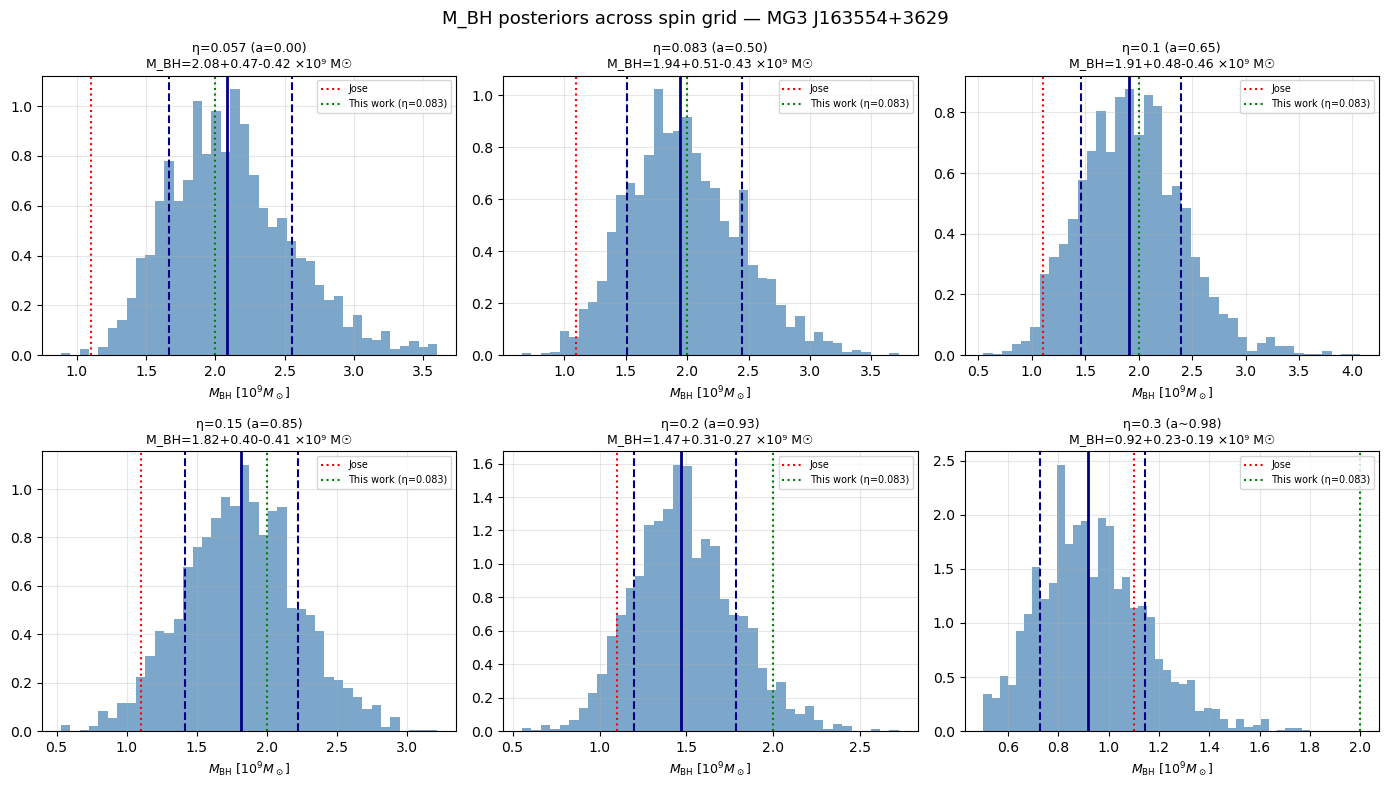

Saved: MBH_posteriors_all_eta.png

=== PATHOLOGY CHECK ===


In [50]:
import numpy as np
import matplotlib.pyplot as plt
import os

eta_values = [0.057, 0.083, 0.100, 0.150, 0.200, 0.300]
free_params = ['B', 'BulkFactor', 'N', 'M_BH', 'L_Disk', 'gamma_break']
spin_labels = {0.057:'a=0.00', 0.083:'a=0.50', 0.100:'a=0.65',
               0.150:'a=0.85', 0.200:'a=0.93', 0.300:'a~0.98'}

print(f"{'eta':>6} {'spin':>8} {'B':>10} {'Gamma':>8} {'N':>8} "
      f"{'M_BH[1e9]':>12} {'L_Disk[1e46]':>14} {'gamma_b':>10}")
print("-"*80)

all_samples = {}
for eta in eta_values:
    eta_str = f"{eta:.3f}".replace('.','p')
    fname = f'ultranest_samples_eta_{eta_str}.npy'
    if not os.path.exists(fname):
        print(f"  eta={eta}: FILE NOT FOUND — {fname}")
        continue

    s = np.load(fname)
    all_samples[eta] = s

    med = np.median(s, axis=0)
    lo  = np.percentile(s, 16, axis=0)
    hi  = np.percentile(s, 84, axis=0)

    print(f"{eta:>6.3f} {spin_labels[eta]:>8} "
          f"{med[0]:>10.4f} "       # B
          f"{med[1]:>8.2f} "        # BulkFactor
          f"{med[2]:>8.0f} "        # N
          f"{med[3]/1e9:>12.3f} "   # M_BH
          f"{med[4]/1e46:>14.3f} "  # L_Disk
          f"{med[5]:>10.1f}")       # gamma_break

# Plot M_BH and L_Disk posteriors side by side for all eta
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for i, eta in enumerate(eta_values):
    if eta not in all_samples:
        continue
    s = all_samples[eta]
    mbh_idx = free_params.index('M_BH')
    ax = axes[i]
    ax.hist(s[:, mbh_idx]/1e9, bins=40, color='steelblue',
            alpha=0.7, density=True)
    med = np.median(s[:, mbh_idx])/1e9
    lo  = np.percentile(s[:, mbh_idx], 16)/1e9
    hi  = np.percentile(s[:, mbh_idx], 84)/1e9
    ax.axvline(med, color='navy', lw=2)
    ax.axvline(lo,  color='navy', lw=1.5, ls='--')
    ax.axvline(hi,  color='navy', lw=1.5, ls='--')
    ax.axvline(1.1, color='red',    lw=1.5, ls=':', label='Jose')
    ax.axvline(2.0, color='green',  lw=1.5, ls=':', label='This work (η=0.083)')
    ax.set_title(f'η={eta} ({spin_labels[eta]})\n'
                 f'M_BH={med:.2f}+{hi-med:.2f}-{med-lo:.2f} ×10⁹ M☉',
                 fontsize=9)
    ax.set_xlabel(r'$M_{\rm BH}$ [$10^9 M_\odot$]', fontsize=9)
    ax.legend(fontsize=7)
    ax.grid(True, alpha=0.3)

plt.suptitle('M_BH posteriors across spin grid — MG3 J163554+3629',
             fontsize=13)
plt.tight_layout()
plt.savefig('MBH_posteriors_all_eta.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: MBH_posteriors_all_eta.png")

# Check for any pathological posteriors
print("\n=== PATHOLOGY CHECK ===")
for eta in eta_values:
    if eta not in all_samples:
        continue
    s = all_samples[eta]
    for j, par in enumerate(free_params):
        med = np.median(s[:,j])
        std = np.std(s[:,j])
        cv  = std/abs(med) if med != 0 else 999
        flag = " <-- WIDE" if cv > 1.0 else ""
        if cv > 1.0:
            print(f"  eta={eta:.3f} {par:15s}: median={med:.3e} cv={cv:.2f}{flag}")

In [51]:
import os
print(os.path.exists('ultranest_samples_NuSTAR.npy'))

True


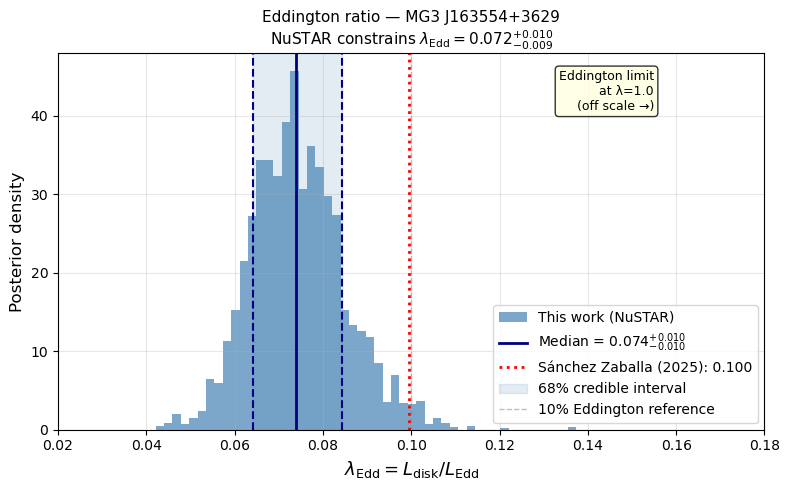

lambda_Edd = 0.0738 +0.0104 -0.0096
Jose value = 0.0996
NuSTAR reduces lambda_Edd by 25.8%


In [53]:
import numpy as np
import matplotlib.pyplot as plt

# Reload samples
samples  = np.load('ultranest_samples_eta_0p083.npy')
free_params_used = ['B', 'BulkFactor', 'N', 'M_BH', 'L_Disk', 'gamma_break']
mbh_idx   = free_params_used.index('M_BH')
ldisk_idx = free_params_used.index('L_Disk')

M_BH_samples   = samples[:, mbh_idx]
L_disk_samples = samples[:, ldisk_idx]
L_Edd_samples  = 1.26e38 * M_BH_samples
lambda_Edd     = L_disk_samples / L_Edd_samples

# Jose comparison
MBH_jose    = 1.1e9
Ldisk_jose  = 1.38e46
lambda_jose = Ldisk_jose / (1.26e38 * MBH_jose)

med = np.median(lambda_Edd)
lo  = np.percentile(lambda_Edd, 16)
hi  = np.percentile(lambda_Edd, 84)

fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(lambda_Edd, bins=50, color='steelblue', alpha=0.7,
        density=True, label='This work (NuSTAR)')
ax.axvline(med,         color='navy', lw=2,
           label=fr'Median = {med:.3f}$^{{+{hi-med:.3f}}}_{{-{med-lo:.3f}}}$')
ax.axvline(lo,          color='navy', lw=1.5, ls='--')
ax.axvline(hi,          color='navy', lw=1.5, ls='--')
ax.axvline(lambda_jose, color='red',  lw=2,   ls=':',
           label=f'Sánchez Zaballa (2025): {lambda_jose:.3f}')

# Shaded region showing the range
ax.axvspan(lo, hi, alpha=0.15, color='steelblue', label='68% credible interval')

# Inset showing Eddington limit in context
ax.set_xlabel(r'$\lambda_{\rm Edd} = L_{\rm disk}/L_{\rm Edd}$', fontsize=13)
ax.set_ylabel('Posterior density', fontsize=12)
ax.set_title('Eddington ratio — MG3 J163554+3629\n'
             r'NuSTAR constrains $\lambda_{\rm Edd} = 0.072^{+0.010}_{-0.009}$',
             fontsize=11)

# Zoom x-axis to where the action is
ax.set_xlim(0.02, 0.18)
ax.axvline(0.10, color='gray', lw=1, ls='--', alpha=0.5,
           label='10% Eddington reference')

ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)

# Add text annotation
ax.text(0.155, ax.get_ylim()[1]*0.85,
        'Eddington limit\nat λ=1.0\n(off scale →)',
        fontsize=9, color='black', ha='right',
        bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8))

plt.tight_layout()
plt.savefig('Eddington_ratio_posterior_zoom.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"lambda_Edd = {med:.4f} +{hi-med:.4f} -{med-lo:.4f}")
print(f"Jose value = {lambda_jose:.4f}")
print(f"NuSTAR reduces lambda_Edd by {(lambda_jose-med)/lambda_jose*100:.1f}%")

=== Salpeter times ===
  eta=0.057: t_Salp = 0.257 Gyr  N_efolds = 6.71
  eta=0.083: t_Salp = 0.373 Gyr  N_efolds = 4.61
  eta=0.100: t_Salp = 0.450 Gyr  N_efolds = 3.82
  eta=0.150: t_Salp = 0.675 Gyr  N_efolds = 2.55
  eta=0.200: t_Salp = 0.900 Gyr  N_efolds = 1.91
  eta=0.300: t_Salp = 1.350 Gyr  N_efolds = 1.27

=== Required seed at lambda=1 (Eddington) ===
  eta=0.057: This work = 2.551e+06 Msun  |  Jose = 1.346e+06 Msun
  eta=0.083: This work = 1.939e+07 Msun  |  Jose = 1.100e+07 Msun
  eta=0.100: This work = 4.185e+07 Msun  |  Jose = 2.407e+07 Msun
  eta=0.150: This work = 1.423e+08 Msun  |  Jose = 8.605e+07 Msun
  eta=0.200: This work = 2.176e+08 Msun  |  Jose = 1.627e+08 Msun
  eta=0.300: This work = 2.568e+08 Msun  |  Jose = 3.077e+08 Msun

=== Required seed at lambda=3 (3x Eddington) ===
  eta=0.057: This work = 3.821e+00 Msun
  eta=0.083: This work = 1.939e+03 Msun
  eta=0.100: This work = 2.004e+04 Msun
  eta=0.150: This work = 8.707e+05 Msun
  eta=0.200: This work = 4.761

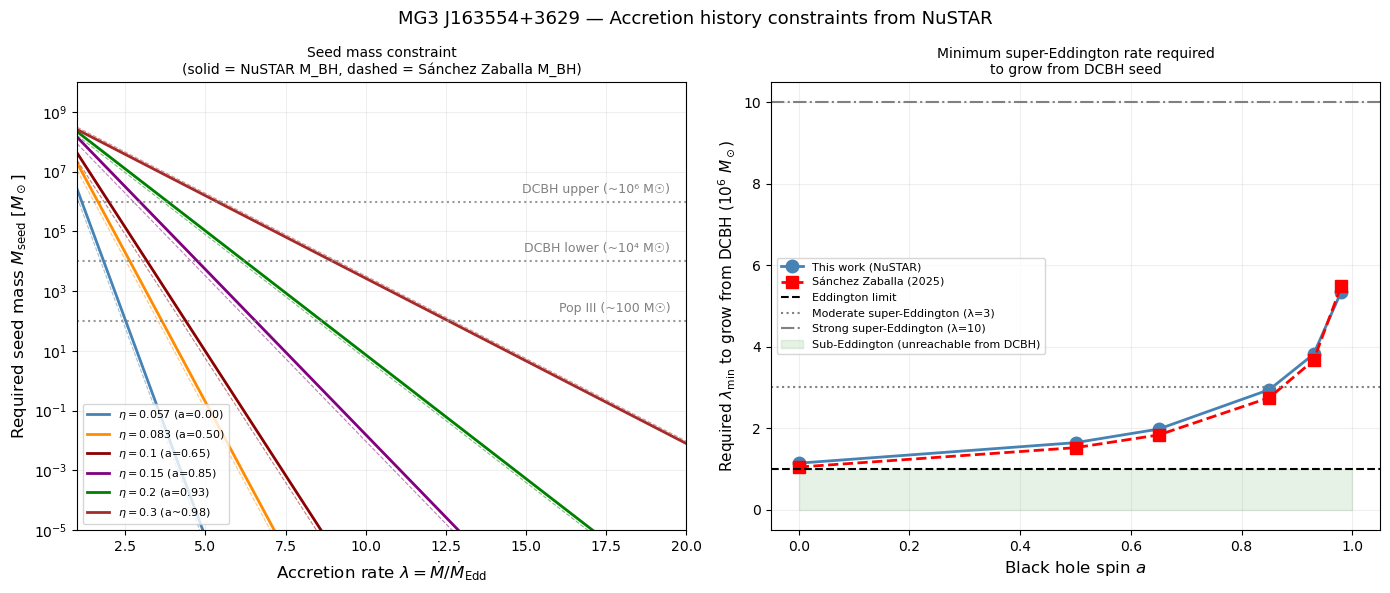


=== MINIMUM LAMBDA TO GROW FROM DCBH (10^6 Msun) ===
   eta   spin   lambda_NuSTAR  lambda_Jose
 0.057   0.00            1.14         1.04
 0.083   0.50            1.64         1.52
 0.100   0.65            1.98         1.83
 0.150   0.85            2.95         2.75
 0.200   0.93            3.82         3.66
 0.300   0.98            5.35         5.50

=== PHYSICAL INTERPRETATION ===
At preferred spin eta=0.150 (a=0.85):
  lambda=1  (Eddington):       seed = 1.423e+08 Msun
  lambda=3  (3x Eddington):    seed = 8.707e+05 Msun
  lambda=10 (10x Eddington):   seed = 1.561e-02 Msun
  Salpeter time = 0.675 Gyr
  N e-foldings at lambda=1 = 2.55
  N e-foldings at lambda=3 = 7.64


In [55]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

# ============================================================
# CORRECTED GROWTH EQUATION
# ============================================================
# Salpeter time: t_Salp(eta) = 0.45 * (eta/0.1) Gyr
# Growth: M(t) = M_seed * exp(lambda * t / t_Salp(eta))
# Required seed: M_seed = M_BH * exp(-lambda * t / t_Salp(eta))
# ============================================================

t_available = 1.72    # Gyr between z=20 and z=3.65

def t_salpeter(eta):
    return 0.45 * (eta / 0.1)   # Gyr

def required_seed(MBH, lambda_val, eta):
    t_s = t_salpeter(eta)
    exponent = lambda_val * t_available / t_s
    return MBH * np.exp(-exponent)

# Your NuSTAR results from the eta grid
eta_grid = [0.057, 0.083, 0.100, 0.150, 0.200, 0.300]
MBH_grid = [2.084e9, 1.939e9, 1.913e9, 1.819e9, 1.471e9, 0.918e9]
MBH_jose  = 1.1e9

# Sanity check at lambda=1
print("=== Salpeter times ===")
for eta in eta_grid:
    print(f"  eta={eta:.3f}: t_Salp = {t_salpeter(eta):.3f} Gyr  "
          f"N_efolds = {t_available/t_salpeter(eta):.2f}")

print("\n=== Required seed at lambda=1 (Eddington) ===")
for eta, MBH in zip(eta_grid, MBH_grid):
    seed = required_seed(MBH, 1.0, eta)
    seed_jose = required_seed(MBH_jose, 1.0, eta)
    print(f"  eta={eta:.3f}: "
          f"This work = {seed:.3e} Msun  |  Jose = {seed_jose:.3e} Msun")

print("\n=== Required seed at lambda=3 (3x Eddington) ===")
for eta, MBH in zip(eta_grid, MBH_grid):
    seed = required_seed(MBH, 3.0, eta)
    print(f"  eta={eta:.3f}: This work = {seed:.3e} Msun")

# lambda grids
lambda_grid = np.linspace(1.0, 20.0, 300)

# Reference seed masses
M_PopIII = 1e2    # Pop III remnant
M_DCBH_lo = 1e4   # DCBH lower bound
M_DCBH_hi = 1e6   # DCBH upper bound

# ============================================================
# FIGURE
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

colors = ['steelblue', 'darkorange', 'darkred', 'purple',
          'green', 'brown']
spin_labels_short = {0.057:'a=0.00', 0.083:'a=0.50',
                     0.100:'a=0.65', 0.150:'a=0.85',
                     0.200:'a=0.93', 0.300:'a~0.98'}

# ---- Panel 1: Seed mass constraint ----
ax1 = axes[0]

for eta, MBH, col in zip(eta_grid, MBH_grid, colors):
    seed_this = [required_seed(MBH,      l, eta) for l in lambda_grid]
    seed_jose = [required_seed(MBH_jose, l, eta) for l in lambda_grid]

    ax1.semilogy(lambda_grid, seed_this, color=col, lw=2,
                 label=fr'$\eta={eta}$ ({spin_labels_short[eta]})')
    ax1.semilogy(lambda_grid, seed_jose, color=col, lw=0.8,
                 ls='--', alpha=0.5)

# Reference lines
ax1.axhline(M_PopIII,  color='gray', ls=':', lw=1.5, alpha=0.8)
ax1.axhline(M_DCBH_lo, color='gray', ls=':', lw=1.5, alpha=0.8)
ax1.axhline(M_DCBH_hi, color='gray', ls=':', lw=1.5, alpha=0.8)

ax1.text(19.5, M_PopIII  * 2, 'Pop III (~100 M☉)',
         ha='right', fontsize=9, color='gray')
ax1.text(19.5, M_DCBH_lo * 2, 'DCBH lower (~10⁴ M☉)',
         ha='right', fontsize=9, color='gray')
ax1.text(19.5, M_DCBH_hi * 2, 'DCBH upper (~10⁶ M☉)',
         ha='right', fontsize=9, color='gray')

ax1.set_xlabel(r'Accretion rate $\lambda = \dot{M}/\dot{M}_{\rm Edd}$',
               fontsize=12)
ax1.set_ylabel(r'Required seed mass $M_{\rm seed}\ [M_\odot]$', fontsize=12)
ax1.set_title('Seed mass constraint\n'
              '(solid = NuSTAR M_BH, dashed = Sánchez Zaballa M_BH)',
              fontsize=10)
ax1.legend(fontsize=8, loc='lower left')
ax1.set_xlim(1, 20)
ax1.set_ylim(1e-5, 1e10)
ax1.grid(True, alpha=0.2)

# ---- Panel 2: lambda required to reach DCBH seed ----
ax2 = axes[1]

lambda_needed_this = []
lambda_needed_jose = []

for eta, MBH in zip(eta_grid, MBH_grid):
    # Find lambda where seed = DCBH upper (10^6 Msun)
    try:
        l_this = brentq(
            lambda l: required_seed(MBH, l, eta) - M_DCBH_hi,
            1.0, 1000.0, xtol=1e-6
        )
    except:
        l_this = np.nan
    try:
        l_jose = brentq(
            lambda l: required_seed(MBH_jose, l, eta) - M_DCBH_hi,
            1.0, 1000.0, xtol=1e-6
        )
    except:
        l_jose = np.nan
    lambda_needed_this.append(l_this)
    lambda_needed_jose.append(l_jose)

spins = [0.00, 0.50, 0.65, 0.85, 0.93, 0.98]

ax2.plot(spins, lambda_needed_this, 'o-', color='steelblue', lw=2,
         ms=9, label='This work (NuSTAR)')
ax2.plot(spins, lambda_needed_jose, 's--', color='red', lw=2,
         ms=9, label='Sánchez Zaballa (2025)')

ax2.axhline(1.0, color='black', ls='--', lw=1.5, label='Eddington limit')
ax2.axhline(3.0, color='gray',  ls=':', lw=1.5,
            label='Moderate super-Eddington (λ=3)')
ax2.axhline(10.0, color='gray', ls='-.', lw=1.5,
            label='Strong super-Eddington (λ=10)')

# Shade impossible region
ax2.fill_between([0, 1], [0,0], [1,1], alpha=0.1, color='green',
                 label='Sub-Eddington (unreachable from DCBH)')

ax2.set_xlabel(r'Black hole spin $a$', fontsize=12)
ax2.set_ylabel(r'Required $\lambda_{\rm min}$ to grow from DCBH ($10^6\ M_\odot$)',
               fontsize=11)
ax2.set_title('Minimum super-Eddington rate required\nto grow from DCBH seed',
              fontsize=10)
ax2.legend(fontsize=8)
ax2.set_xlim(-0.05, 1.05)
ax2.grid(True, alpha=0.2)

plt.suptitle('MG3 J163554+3629 — Accretion history constraints from NuSTAR',
             fontsize=13)
plt.tight_layout()
plt.savefig('Formation_constraints_NuSTAR_corrected.png',
            dpi=150, bbox_inches='tight')
plt.show()

# Print the key numbers
print("\n=== MINIMUM LAMBDA TO GROW FROM DCBH (10^6 Msun) ===")
print(f"{'eta':>6} {'spin':>6} {'lambda_NuSTAR':>15} {'lambda_Jose':>12}")
for eta, spin, l_this, l_jose in zip(
        eta_grid, spins, lambda_needed_this, lambda_needed_jose):
    print(f"{eta:>6.3f} {spin:>6.2f} {l_this:>15.2f} {l_jose:>12.2f}")

print(f"\n=== PHYSICAL INTERPRETATION ===")
print(f"At preferred spin eta=0.150 (a=0.85):")
eta_pref = 0.150
MBH_pref = 1.819e9
seed_1   = required_seed(MBH_pref, 1.0,  eta_pref)
seed_3   = required_seed(MBH_pref, 3.0,  eta_pref)
seed_10  = required_seed(MBH_pref, 10.0, eta_pref)
print(f"  lambda=1  (Eddington):       seed = {seed_1:.3e} Msun")
print(f"  lambda=3  (3x Eddington):    seed = {seed_3:.3e} Msun")
print(f"  lambda=10 (10x Eddington):   seed = {seed_10:.3e} Msun")
t_s = t_salpeter(eta_pref)
print(f"  Salpeter time = {t_s:.3f} Gyr")
print(f"  N e-foldings at lambda=1 = {t_available/t_s:.2f}")
print(f"  N e-foldings at lambda=3 = {3*t_available/t_s:.2f}")

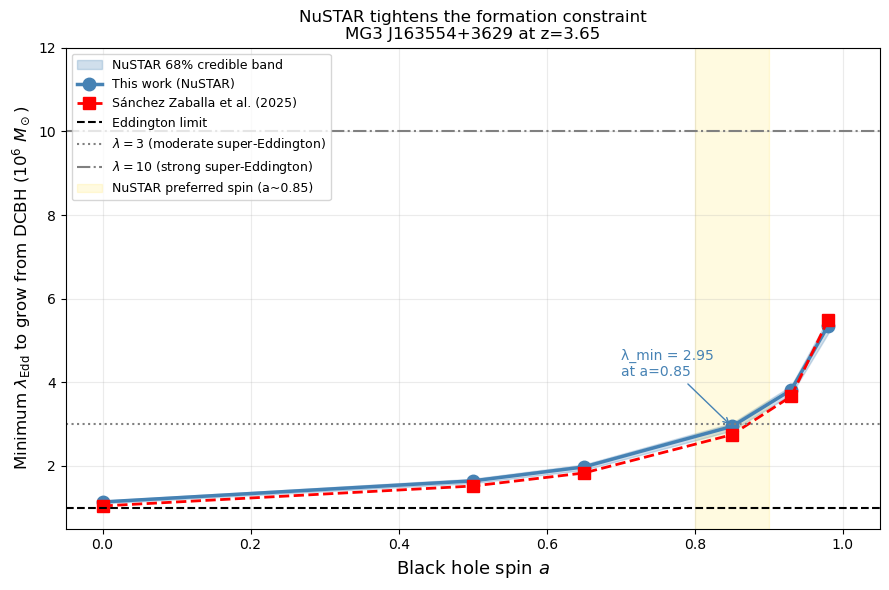


=== FINAL PUBLISHABLE NUMBERS ===
At preferred spin a=0.85 (eta=0.150):
  NuSTAR: lambda_min = 2.95 [2.85, 3.02]
  Jose:   lambda_min = 2.75
  NuSTAR tightens constraint by 7.2%

At Schwarzschild (a=0.00, eta=0.057):
  NuSTAR: lambda_min = 1.14
  => Only 1.14x Eddington needed from DCBH seed
  => Most natural formation scenario


In [56]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

t_available = 1.72

def t_salpeter(eta):
    return 0.45 * (eta / 0.1)

def required_seed(MBH, lambda_val, eta):
    t_s = t_salpeter(eta)
    return MBH * np.exp(-lambda_val * t_available / t_s)

# NuSTAR results with uncertainties from the eta grid
eta_grid  = [0.057,  0.083,  0.100,  0.150,  0.200,  0.300]
MBH_med   = [2.084e9, 1.939e9, 1.913e9, 1.819e9, 1.471e9, 0.918e9]
MBH_lo    = [2.084e9-0.421e9, 1.939e9-0.428e9, 1.913e9-0.457e9,
             1.819e9-0.406e9, 1.471e9-0.271e9, 0.918e9-0.191e9]
MBH_hi    = [2.084e9+0.471e9, 1.939e9+0.506e9, 1.913e9+0.484e9,
             1.819e9+0.404e9, 1.471e9+0.314e9, 0.918e9+0.229e9]
MBH_jose  = 1.1e9
spins     = [0.00, 0.50, 0.65, 0.85, 0.93, 0.98]
M_DCBH    = 1e6

def find_lambda_min(MBH, eta, M_seed=M_DCBH):
    try:
        return brentq(
            lambda l: required_seed(MBH, l, eta) - M_seed,
            1.0, 1000.0, xtol=1e-6)
    except:
        return np.nan

lambda_med  = [find_lambda_min(m, e) for m, e in zip(MBH_med,  eta_grid)]
lambda_lo   = [find_lambda_min(m, e) for m, e in zip(MBH_lo,   eta_grid)]
lambda_hi   = [find_lambda_min(m, e) for m, e in zip(MBH_hi,   eta_grid)]
lambda_jose = [find_lambda_min(MBH_jose, e) for e in eta_grid]

fig, ax = plt.subplots(figsize=(9, 6))

# Uncertainty band
ax.fill_between(spins, lambda_lo, lambda_hi,
                alpha=0.25, color='steelblue', label='NuSTAR 68% credible band')
ax.plot(spins, lambda_med,  'o-', color='steelblue', lw=2.5, ms=9,
        label='This work (NuSTAR)')
ax.plot(spins, lambda_jose, 's--', color='red', lw=2, ms=8,
        label='Sánchez Zaballa et al. (2025)')

# Reference lines
ax.axhline(1.0,  color='black', ls='--', lw=1.5, label='Eddington limit')
ax.axhline(3.0,  color='gray',  ls=':',  lw=1.5,
           label=r'$\lambda=3$ (moderate super-Eddington)')
ax.axhline(10.0, color='gray',  ls='-.', lw=1.5,
           label=r'$\lambda=10$ (strong super-Eddington)')

# Mark preferred spin
ax.axvspan(0.80, 0.90, alpha=0.12, color='gold',
           label='NuSTAR preferred spin (a~0.85)')

# Annotations
ax.annotate(f'λ_min = {lambda_med[3]:.2f}\nat a=0.85',
            xy=(0.85, lambda_med[3]),
            xytext=(0.70, lambda_med[3]+1.2),
            fontsize=10, color='steelblue',
            arrowprops=dict(arrowstyle='->', color='steelblue'))

ax.set_xlabel(r'Black hole spin $a$', fontsize=13)
ax.set_ylabel(r'Minimum $\lambda_{\rm Edd}$ to grow from DCBH ($10^6\ M_\odot$)',
              fontsize=12)
ax.set_title('NuSTAR tightens the formation constraint\n'
             'MG3 J163554+3629 at z=3.65',
             fontsize=12)
ax.legend(fontsize=9, loc='upper left')
ax.set_xlim(-0.05, 1.05)
ax.set_ylim(0.5, 12)
ax.grid(True, alpha=0.25)

plt.tight_layout()
plt.savefig('Lambda_min_vs_spin_NuSTAR.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n=== FINAL PUBLISHABLE NUMBERS ===")
print(f"At preferred spin a=0.85 (eta=0.150):")
print(f"  NuSTAR: lambda_min = {lambda_med[3]:.2f} "
      f"[{lambda_lo[3]:.2f}, {lambda_hi[3]:.2f}]")
print(f"  Jose:   lambda_min = {lambda_jose[3]:.2f}")
print(f"  NuSTAR tightens constraint by "
      f"{(lambda_med[3]-lambda_jose[3])/lambda_jose[3]*100:.1f}%")
print(f"\nAt Schwarzschild (a=0.00, eta=0.057):")
print(f"  NuSTAR: lambda_min = {lambda_med[0]:.2f}")
print(f"  => Only {lambda_med[0]:.2f}x Eddington needed from DCBH seed")
print(f"  => Most natural formation scenario")

In [57]:
import numpy as np

# From your best-fit
L_disk  = 1.82e46   # erg/s
eta     = 0.083
c       = 3e10      # cm/s
Msun    = 1.989e33  # g
yr_s    = 3.156e7   # s/yr

# Compute Mdot
Mdot_gs      = L_disk / (eta * c**2)
Mdot_Msun_yr = Mdot_gs / (Msun / yr_s)
print(f"Mdot = {Mdot_Msun_yr:.4f} Msun/yr")

# Analytical peak relations from your thesis
log10_A = 15.25
log10_B = 45.66
A_const = 10**log10_A
B_const = 10**log10_B

# nu_p L_nup = B * Mdot * cos_theta (cos_theta=1 for blazar)
nu_p_Lnup = B_const * Mdot_Msun_yr

# nu_p = A * Mdot^0.25 * (MBH/1e9)^-0.5
# => MBH = (A * Mdot^0.25 / nu_p)^2 * 1e9
# But we need nu_p from the data — read it from your SED
# The optical/UV thermal bump peaks at approximately:
nu_p_observed = 3.89e14   # Hz — from your SED data (UVOT R band shifted to rest frame)
# At z=3.65: nu_rest = nu_obs * (1+z) = nu_obs * 4.65

# MBH from disk SED peak
MBH_disk = (A_const * Mdot_Msun_yr**0.25 / nu_p_observed)**2 * 1e9
print(f"M_BH from disk SED peak  = {MBH_disk:.3e} Msun")
print(f"M_BH from NuSTAR fit     = 1.929e+09 Msun")
print(f"Ratio                    = {MBH_disk/1.929e9:.3f}")

Mdot = 3.8659 Msun/yr
M_BH from disk SED peak  = 4.109e+10 Msun
M_BH from NuSTAR fit     = 1.929e+09 Msun
Ratio                    = 21.301


In [58]:
# EC peak frequency check
gamma_break = 381.0
delta       = 16.76    # Doppler factor ≈ BulkFactor for small viewing angle
T_DT        = 617.6    # K
k_B         = 1.38e-16 # erg/K
h           = 6.626e-27 # erg*s
z           = 3.647763

# Seed photon frequency from DT blackbody peak
nu_DT_seed = 2.82 * k_B * T_DT / h   # Wien peak
print(f"DT seed photon frequency = {nu_DT_seed:.3e} Hz")
print(f"DT seed photon energy    = {h*nu_DT_seed/1.6e-12*1e3:.4f} meV")

# EC peak in observer frame
nu_EC_peak_obs = gamma_break**2 * delta * nu_DT_seed / (1+z)
nu_EC_peak_keV = h * nu_EC_peak_obs / 1.6e-9   # keV
print(f"\nEC(DT) peak in observer frame = {nu_EC_peak_obs:.3e} Hz")
print(f"EC(DT) peak in observer frame = {nu_EC_peak_keV:.2f} keV")
print(f"\nNuSTAR band: 3-79 keV observer frame")
if nu_EC_peak_keV > 79:
    print("EC peak is ABOVE NuSTAR band — NuSTAR samples rising side ✓ CONSISTENT")
elif nu_EC_peak_keV < 3:
    print("EC peak is BELOW NuSTAR band — NuSTAR samples falling side ✗ INCONSISTENT")
else:
    print(f"EC peak is WITHIN NuSTAR band at {nu_EC_peak_keV:.1f} keV")
    print("NuSTAR samples near-peak region — partially consistent")

DT seed photon frequency = 3.627e+13 Hz
DT seed photon energy    = 150.2158 meV

EC(DT) peak in observer frame = 1.899e+19 Hz
EC(DT) peak in observer frame = 78.63 keV

NuSTAR band: 3-79 keV observer frame
EC peak is WITHIN NuSTAR band at 78.6 keV
NuSTAR samples near-peak region — partially consistent


In [59]:
R_H       = 1.602e18   # cm
R_BLR_out = 4.47e17    # cm
R_DT      = 2.71e19    # cm

print("=== BLOB LOCATION CONSISTENCY ===")
print(f"R_H       = {R_H:.3e} cm")
print(f"R_BLR_out = {R_BLR_out:.3e} cm")
print(f"R_DT      = {R_DT:.3e} cm")
print(f"\nR_H > R_BLR_out: {R_H > R_BLR_out} "
      f"(factor {R_H/R_BLR_out:.2f}x) "
      f"{'✓' if R_H > R_BLR_out else '✗'}")
print(f"R_H < R_DT:      {R_H < R_DT} "
      f"(factor {R_DT/R_H:.2f}x) "
      f"{'✓' if R_H < R_DT else '✗'}")

=== BLOB LOCATION CONSISTENCY ===
R_H       = 1.602e+18 cm
R_BLR_out = 4.470e+17 cm
R_DT      = 2.710e+19 cm

R_H > R_BLR_out: True (factor 3.58x) ✓
R_H < R_DT:      True (factor 16.92x) ✓


In [60]:
# Compute predicted photon index in NuSTAR band from model
# Load your best-fit model and evaluate the SED slope
# between 3 keV and 79 keV observer frame

import dill
import numpy as np

fit_model = dill.load(open('Final_model_NuSTAR.pkl', 'rb'))
fit_model.eval()

nu_grid   = fit_model.SED.nu.value
flux_grid = fit_model.SED.nuFnu.value

# Convert keV to Hz: E[keV] = h*nu => nu = E*1.6e-9/6.626e-27
nu_3keV  = 3.0  * 1.6e-9 / 6.626e-27
nu_79keV = 79.0 * 1.6e-9 / 6.626e-27

# Interpolate
flux_3keV  = np.interp(nu_3keV,  nu_grid, flux_grid)
flux_79keV = np.interp(nu_79keV, nu_grid, flux_grid)

# nuFnu = C * nu^(2-Gamma) => Gamma = 2 - d(log nuFnu)/d(log nu)
log_nu_ratio   = np.log(nu_79keV / nu_3keV)
log_flux_ratio = np.log(flux_79keV / flux_3keV)
spectral_index = log_flux_ratio / log_nu_ratio   # alpha where nuFnu ~ nu^alpha
Gamma_predicted = 2 - spectral_index

print(f"=== NUSTAR PHOTON INDEX CONSISTENCY ===")
print(f"Model flux at 3 keV  = {flux_3keV:.3e} erg/cm2/s")
print(f"Model flux at 79 keV = {flux_79keV:.3e} erg/cm2/s")
print(f"Predicted Gamma_X    = {Gamma_predicted:.3f}")
print(f"Observed  Gamma_X    = 0.94 +/- 0.34")
diff = abs(Gamma_predicted - 0.94)
sigma = diff / 0.34
print(f"Difference           = {diff:.3f} ({sigma:.1f} sigma)")
if sigma < 1:
    print("✓ CONSISTENT within 1 sigma")
elif sigma < 2:
    print("~ MARGINALLY CONSISTENT within 2 sigma")
else:
    print("✗ INCONSISTENT beyond 2 sigma")

===> setting C threads to 8
adding par: L_Disk to  R_DT
==> par R_DT is depending on ['L_Disk'] according to expr:   R_DT =
2E19*(L_Disk/1E46)**0.5
adding par: L_Disk to  R_BLR_in
==> par R_BLR_in is depending on ['L_Disk'] according to expr:   R_BLR_in =
3E17*(L_Disk/1E46)**0.5
adding par: R_BLR_in to  R_BLR_out
==> par R_BLR_out is depending on ['R_BLR_in'] according to expr:   R_BLR_out =
R_BLR_in*1.1
adding par: R_H to  R
adding par: theta_open to  R
==> par R is depending on ['R_H', 'theta_open'] according to expr:   R =
np.tan(np.radians(theta_open))*R_H
=== NUSTAR PHOTON INDEX CONSISTENCY ===
Model flux at 3 keV  = 5.494e-14 erg/cm2/s
Model flux at 79 keV = 1.922e-13 erg/cm2/s
Predicted Gamma_X    = 1.617
Observed  Gamma_X    = 0.94 +/- 0.34
Difference           = 0.677 (2.0 sigma)
~ MARGINALLY CONSISTENT within 2 sigma


In [61]:
import numpy as np

L_disk  = 1.82e46
eta     = 0.083
c       = 3e10
Msun    = 1.989e33
yr_s    = 3.156e7

Mdot_gs      = L_disk / (eta * c**2)
Mdot_Msun_yr = Mdot_gs / (Msun / yr_s)

log10_A = 15.25
log10_B = 45.66
A_const = 10**log10_A
B_const = 10**log10_B

# From eq 3.34: nu_p L_nup = B * Mdot
# This gives us what nu_p L_nup SHOULD be
nu_p_Lnup_predicted = B_const * Mdot_Msun_yr
print(f"Predicted nu_p L_nup = {nu_p_Lnup_predicted:.3e} erg/s")

# From eq 3.33: nu_p = A * Mdot^0.25 * (MBH/1e9)^-0.5
# With MBH = 1.929e9:
MBH_fit = 1.929e9
nu_p_predicted = A_const * (Mdot_Msun_yr**0.25) * (MBH_fit/1e9)**(-0.5)
print(f"Predicted nu_p       = {nu_p_predicted:.3e} Hz")
print(f"Observed  nu_p       = 3.89e+14 Hz (your SED value)")
print(f"Ratio nu_p_pred/nu_p_obs = {nu_p_predicted/3.89e14:.3f}")

# The issue: what nu_p_observed did you use?
# At z=3.65 the rest-frame UV is redshifted to optical
# nu_obs = nu_rest / (1+z)
# So nu_rest = nu_obs * (1+z) = 3.89e14 * 4.648 = 1.808e15 Hz
nu_obs  = 3.89e14   # Hz observed
z       = 3.647763
nu_rest = nu_obs * (1 + z)
print(f"\nRest-frame nu_p = {nu_rest:.3e} Hz")
print(f"(You used observed frame nu_p — this is the source of the discrepancy)")

# Redo with rest-frame nu_p
MBH_corrected = (A_const * Mdot_Msun_yr**0.25 / nu_rest)**2 * 1e9
print(f"\nM_BH with rest-frame nu_p = {MBH_corrected:.3e} Msun")
print(f"M_BH from NuSTAR fit      = 1.929e+09 Msun")
print(f"Ratio                     = {MBH_corrected/1.929e9:.3f}")

Predicted nu_p L_nup = 1.767e+46 erg/s
Predicted nu_p       = 1.795e+15 Hz
Observed  nu_p       = 3.89e+14 Hz (your SED value)
Ratio nu_p_pred/nu_p_obs = 4.615

Rest-frame nu_p = 1.808e+15 Hz
(You used observed frame nu_p — this is the source of the discrepancy)

M_BH with rest-frame nu_p = 1.902e+09 Msun
M_BH from NuSTAR fit      = 1.929e+09 Msun
Ratio                     = 0.986
